# PathSnap preprocessing: flags, labelling, candidates, features (stage 1: sections 4.1 - 4.3)

Builds the model-ready candidate-ranking table. **No model is trained here.**
Formulation: per GPS point -> candidate arcs -> features per (point, candidate) -> label 1 if the candidate is the
reference arc. Networks are **per trip**, so `arc_id` is local and never a global class.

Partitions used: **train (80 trips)** and **student_test (10 trips)**. The evaluator partition is never opened.
Index spaces (never joined by row number): `gps_row`, `node_id` (local), `arc_id` (local), `route_pos`.

This notebook covers 4.1 (loader), 4.2 (point flags), 4.3 (route-constrained labelling). Sections 4.4+ follow after review.
Thresholds come from the EDA `CONFIG` cell (the EDA's `outputs/preprocessing_config.json` is git-ignored and is not in the repo).

## 4.1 Setup, config and per-trip loader

In [1]:
"""Setup: imports, paths, config. Restart-and-Run-All safe."""
import sys, time, json, random
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, folium
from pyproj import Transformer

HERE = Path.cwd()
sys.path.insert(0, str(HERE))                       # make pathsnap_prep importable from the notebook folder
import pathsnap_prep as P

CONFIG = dict(P.CONFIG)                              # every threshold + reason is documented in pathsnap_prep.CONFIG
random.seed(CONFIG["seed"]); np.random.seed(CONFIG["seed"])
ROOT = P.find_repo_root(HERE)                        # repository root (folder holding Dataset/)
DATA = ROOT / "Dataset"
CACHE = HERE / "cache"                               # per-trip projected arrays (git-ignored)
OUTD = ROOT / "data_preprocessing" / "cleaned_data"  # cleaned/processed tables are written here
VAL = OUTD / "validation"; VAL.mkdir(parents=True, exist_ok=True)
MODEL = OUTD / "model_data"; MODEL.mkdir(parents=True, exist_ok=True)   # model-ready tables (see 4.7)
# Only train and student_test are listed; the evaluator partition is never touched.
SPLITS = {"train": P.list_trips(DATA, "train"), "student_test": P.list_trips(DATA, "student_test")}
print({k: len(v) for k, v in SPLITS.items()}, "| config keys:", len(CONFIG))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

{'train': 80, 'student_test': 10} | config keys: 33


In [2]:
"""Load every trip once (projects to its own UTM zone, derives arc geometry, caches to disk). No route is read."""
trips = {}                                           # (split, trip_id) -> Trip
t0 = time.time(); inv = []
for split, ids in SPLITS.items():
    for tid in ids:
        tr = P.load_trip(DATA, split, tid, CACHE)
        P.assert_index_spaces(tr)                    # index-space assertions
        # projection round trip: UTM -> lon/lat must reproduce the raw GPS to < 1e-6 deg (~0.1 m)
        back = Transformer.from_crs(tr.epsg, 4326, always_xy=True).transform(tr.gps_xy[:, 0], tr.gps_xy[:, 1])
        assert np.abs(back[0] - tr.gps_lonlat[:, 0]).max() < 1e-6 and np.abs(back[1] - tr.gps_lonlat[:, 1]).max() < 1e-6
        trips[(split, tid)] = tr
        inv.append(dict(split=split, trip_id=tid, epsg=tr.epsg, n_gps=tr.n_gps, n_nodes=len(tr.node_xy), n_arcs=tr.n_arcs,
                        median_arc_len_m=float(np.median(tr.arc_len)), zero_len_arcs=int((tr.arc_len == 0).sum()),
                        one_way_arc_share=float(1 - tr.arc_has_reverse.mean())))
inv = pd.DataFrame(inv); inv.to_csv(VAL / "trip_inventory.csv", index=False)
print("loaded %d trips in %.0fs" % (len(trips), time.time() - t0))
display(inv.groupby("split")[["n_gps", "n_nodes", "n_arcs", "median_arc_len_m", "zero_len_arcs", "one_way_arc_share"]].describe().T.round(2))
print("UTM zones used:", inv.epsg.value_counts().to_dict())

loaded 90 trips in 1s


split                    student_test      train
n_gps             count         10.00      80.00
                  mean        1916.00    2605.21
                  std         1335.43    3312.35
                  min          262.00     361.00
                  25%          917.75     945.75
                  50%         1420.00    1529.00
                  75%         2872.00    2792.75
                  max         3958.00   19313.00
n_nodes           count         10.00      80.00
                  mean        9068.90   24168.56
                  std         7452.18   32272.30
                  min         1770.00     299.00
                  25%         4908.00    3487.75
                  50%         6596.50    9608.00
                  75%        11844.25   28846.75
                  max        26635.00  155003.00
n_arcs            count         10.00      80.00
                  mean       18504.10   48461.30
                  std        15496.93   64738.84
                  min         3577.00     649.00
                  25%        10292.25    7061.75
                  50%        13145.00   19526.50
                  75%        24818.50   58003.25
                  max        56027.00  307392.00
median_arc_len_m  count         10.00      80.00
                  mean          31.40      30.39
                  std           12.14      15.75
                  min           15.85       6.75
                  25%           20.24      21.48
                  50%           31.95      24.58
                  75%           40.12      35.11
                  max           53.34      85.14
zero_len_arcs     count         10.00      80.00
                  mean           0.60       1.25
                  std            0.97       2.37
                  min            0.00       0.00
                  25%            0.00       0.00
                  50%            0.00       0.00
                  75%            1.50       2.00
                  max            2.00      14.00
one_way_arc_share count         10.00      80.00
                  mean           0.07       0.08
                  std            0.06       0.09
                  min            0.00       0.00
                  25%            0.02       0.02
                  50%            0.07       0.05
                  75%            0.13       0.10
                  max            0.14       0.65

UTM zones used: {32637: 10, 32630: 9, 32632: 8, 32633: 7, 32631: 7, 32636: 5, 32634: 5, 32638: 4, 32641: 4, 32639: 4, 32629: 3, 32635: 3, 32617: 3, 32653: 3, 32616: 2, 32640: 2, 32643: 2, 32615: 2, 32648: 1, 32614: 1, 32651: 1, 32622: 1, 32735: 1, 32721: 1, 32722: 1}


### Findings and decision

- 90 trips loaded (80 train, 10 student_test); every trip projected to its own UTM zone (25 distinct EPSG codes: trips are spread worldwide, so one global CRS would be wrong). Projection round trip error < 1e-6 deg.
- Index-space assertions pass for all trips. Train trips are larger (median 9.6k nodes, max 155k) than student-test (median 6.6k).
- Zero-length arcs exist (up to 14 in one trip); they are kept (never delete arcs) and handled by a length guard in the distance code.
- Decision: `route` is never read by the loader; it is read only by `load_route`, used for labels.

## 4.2 Point flags (all partitions) and the training-only drop rule

In [3]:
"""Per-point flags for every trip. Only the TRAINING partition may drop rows, and only for the three removable rules."""
flag_tables, drop_log = {"train": [], "student_test": []}, []
for (split, tid), tr in trips.items():
    f = P.point_flags(tr, CONFIG); f.insert(0, "trip_id", tid)
    kept, removed = P.apply_training_drop(f, split)          # student_test is returned untouched
    drop_log.append(dict(split=split, trip_id=tid, n_rows=len(f), **removed, n_dropped=len(f) - len(kept)))
    flag_tables[split].append(f)                             # keep ALL rows incl. flags; the drop is applied via `removable` later
flags = {s: pd.concat(v, ignore_index=True) for s, v in flag_tables.items()}
drop_log = pd.DataFrame(drop_log); drop_log.to_csv(VAL / "drop_log.csv", index=False)
cols = ["exact_duplicate", "invalid_coord", "non_monotonic_ts", "stationary", "in_hive", "after_gap", "speed_jump", "speed_outlier"]
summary = pd.DataFrame({s: flags[s][cols].sum() for s in flags}); summary.loc["rows"] = [len(flags[s]) for s in flags]
display(summary)
print("rows removed per rule (TRAIN only):", drop_log[drop_log.split == "train"][["exact_duplicate", "invalid_coord", "non_monotonic_ts", "n_dropped"]].sum().to_dict())
print("student_test rows dropped:", int(drop_log[drop_log.split == "student_test"].n_dropped.sum()))

,train,student_test
exact_duplicate,0,0
invalid_coord,0,0
non_monotonic_ts,0,0
stationary,1427,80
in_hive,410,43
after_gap,1216,44
speed_jump,1530,8
speed_outlier,2055,53
rows,208417,19160


rows removed per rule (TRAIN only): {'exact_duplicate': 0, 'invalid_coord': 0, 'non_monotonic_ts': 0, 'n_dropped': 0}
student_test rows dropped: 0


In [4]:
"""How do speed jumps relate to GPS gaps? (A jump right after a gap is an averaged speed, not necessarily a GPS error.)"""
rows = []
for s in flags:
    f = flags[s]
    rows.append(dict(split=s, speed_jumps=int(f.speed_jump.sum()), jumps_after_gap=int((f.speed_jump & f.after_gap).sum()),
                     jumps_not_after_gap=int((f.speed_jump & ~f.after_gap).sum()), long_gap_events=int(f.after_gap.sum()),
                     max_gap_s=float(f.gap_len_s.max())))
display(pd.DataFrame(rows))
# Are the non-gap speed jumps isolated GPS errors, or whole trips running above 50 m/s (a threshold issue)?
per_trip = flags["train"].groupby("trip_id").agg(jumps=("speed_jump", "sum"), n=("speed_jump", "size"), p50_speed=("speed_mps", "median"),
                                                  p99_speed=("speed_mps", lambda x: np.nanpercentile(x, 99)))
per_trip["jump_share"] = per_trip.jumps / per_trip.n
display(per_trip.sort_values("jumps", ascending=False).head(8).round(3))
print("train trips with >=1 jump:", int((per_trip.jumps > 0).sum()), "| trips where >20% of points exceed 50 m/s:", int((per_trip.jump_share > .2).sum()))

,split,speed_jumps,jumps_after_gap,jumps_not_after_gap,long_gap_events,max_gap_s
0,train,1530,0,1530,1216,153064.0
1,student_test,8,0,8,44,210.0


,jumps,n,p50_speed,p99_speed,jump_share
trip_id,,,,,
00000032,892,2464,41.037,71.742,0.362
00000001,340,1315,41.365,64.018,0.259
00000013,112,2580,28.487,91.170,0.043
00000024,44,801,34.404,56.775,0.055
00000043,34,2322,29.037,51.562,0.015
00000028,21,3565,25.777,48.276,0.006
00000055,18,2472,34.457,49.396,0.007
00000053,7,1304,22.666,44.616,0.005


train trips with >=1 jump: 39 | trips where >20% of points exceed 50 m/s: 2


In [5]:
"""Save the flag tables (all rows, nothing removed) for later stages."""
for s, name in [("train", "point_flags_train"), ("student_test", "point_flags_student")]:
    flags[s].to_parquet(OUTD / f"{name}.parquet", index=False)
DQ = [dict(stage="4.2", partition=s, item=c, value=int(flags[s][c].sum()), note="flag count") for s in flags for c in cols]
def log_decision(stage, item, value, note=""):
    """Append one decision/measurement to the data-quality log (rewritten on every call so Restart-and-Run-All is idempotent)."""
    DQ.append(dict(stage=stage, partition="train", item=item, value=value, note=note))
    pd.DataFrame(DQ).to_csv(OUTD / "data_quality_log.csv", index=False)
pd.DataFrame(DQ).to_csv(OUTD / "data_quality_log.csv", index=False); print("saved flag tables + data_quality_log.csv")

saved flag tables + data_quality_log.csv


### Findings and decision

- Removable-in-training rules (duplicates, invalid coordinates, non-monotonic time) removed **0 rows**, matching the EDA. Student-test: 0 rows dropped by construction.
- Flags kept and not dropped: stationary 1,427 / 80, in_hive 410 / 43, after_gap 1,216 / 44 (train / student), speed_outlier 2,055 / 53 (EDA reported 2,084 train; small difference because the median/MAD here excludes gap-averaged speeds).
- **All 1,530 train speed jumps (>50 m/s) are NOT after a gap** (0 coincide with gaps). 1,232 of them are in just two trips (00000032 and 00000001) whose median speed is already ~41 m/s (~150 km/h, likely motorway). So the 50 m/s rule mostly flags fast roads, not GPS errors; it is kept as a flag only and should not be used to drop rows or heavily down-weight.
- Decision: keep every point; flags become features / sample-weight inputs later.

## 4.3 Per-point labelling by route-constrained alignment (train + student_test)

`.route` is a sequence of arcs, not a per-point label. States = **route positions** (so loops are handled), emission = capped
Gaussian on the point-to-arc distance, transitions = monotone (stay / advance / small forward skip; larger skips only as
`dt` grows or after a long gap). First we reproduce the EDA's 1.3% nearest-vs-monotonic disagreement.

In [6]:
"""Reproduce the EDA label-rule pilot exactly: 150 evenly spaced points, nearest route arc vs a GREEDY monotonic rule."""
from shapely.geometry import Point
from shapely.strtree import STRtree
def eda_rule(tr, route, n_samples=150):
    g = list(tr.arc_geoms()[route])                                   # geometry of route[route_pos]
    idx = np.linspace(0, tr.n_gps - 1, min(n_samples, tr.n_gps), dtype=int)     # gps_row samples
    pts = [Point(*tr.gps_xy[i]) for i in idx]
    npos = np.asarray(STRtree(g).nearest(pts), dtype=int)             # route_pos of the nearest route arc
    last, mono = 0, []
    for p in pts:                                                     # greedy: only route_pos >= last is searched, take the nearest
        last += int(np.argmin([p.distance(g[i]) for i in range(last, len(g))])); mono.append(last)
    return idx, npos, np.asarray(mono)
res = []
for tid in SPLITS["train"]:
    tr = trips[("train", tid)]; route = P.load_route(DATA, "train", tid, tr.n_arcs)
    idx, npos, mono = eda_rule(tr, route); res.append(dict(trip_id=tid, nearest_vs_greedy_agreement=float(np.mean(route[npos] == route[mono]))))
res = pd.DataFrame(res).sort_values("nearest_vs_greedy_agreement")
display(res.head(6).round(3)); print("trips with agreement < 50%:", int((res.nearest_vs_greedy_agreement < .5).sum()), "of", len(res))

,trip_id,nearest_vs_greedy_agreement
38,00000046,0.013
64,00000081,0.020
8,00000011,0.027
40,00000048,0.033
55,00000069,0.033
49,00000061,0.073


trips with agreement < 50%: 8 of 80


In [7]:
"""Diagnose the worst trip: where do the greedy monotonic rule and the nearest-arc rule disagree?"""
worst = res.trip_id.iloc[0]; tr = trips[("train", worst)]; route = P.load_route(DATA, "train", worst, tr.n_arcs)
idx, npos, mono = eda_rule(tr, route)
g0 = tr.arc_geoms()[route]
print(f"trip {worst}: {tr.n_gps} GPS rows, route has {len(route)} positions ({len(set(route))} distinct arcs)")
print("nearest route_pos, first 12 samples:", npos[:12].tolist())
print("greedy  route_pos, first 12 samples:", mono[:12].tolist())
print("first GPS fix -> route_pos 0 / last (m): %.1f / %.1f" % (Point(*tr.gps_xy[0]).distance(g0[0]), Point(*tr.gps_xy[0]).distance(g0[-1])))
print("last  GPS fix -> route_pos 0 / last (m): %.1f / %.1f" % (Point(*tr.gps_xy[-1]).distance(g0[0]), Point(*tr.gps_xy[-1]).distance(g0[-1])))

trip 00000046: 1401 GPS rows, route has 66 positions (66 distinct arcs)
nearest route_pos, first 12 samples: [64, 65, 2, 2, 2, 3, 3, 4, 5, 7, 9, 11]
greedy  route_pos, first 12 samples: [64, 65, 65, 65, 65, 65, 65, 65, 65, 65, 65, 65]
first GPS fix -> route_pos 0 / last (m): 11.4 / 11.4
last  GPS fix -> route_pos 0 / last (m): 24.5 / 24.5


### Findings and decision

- Reproduced the EDA 1.3%: it is **train trip 00000046** (8 of 80 train trips are below 50% agreement). It is not an indexing bug.
- Cause: the greedy monotonic rule only searches route positions >= the last one. In 00000046 the trip starts near the END of the route (route is a loop; first fix is 11.4 m from both route_pos 0 and the last arc), so greedy jumps to position 65 of 66 on the first samples and can never move back. Nearest-arc is right; the greedy rule is wrong. The same happens in 00000081, 00000011, 00000048, 00000069, 00000061.
- Decision: do not use greedy monotonic or nearest-arc labels. Use the global route-position Viterbi, which resolves loops because the start position is chosen jointly with the rest of the path.

In [8]:
"""Run the aligner on every trip (train + student_test); keep per-point labels and per-trip validation numbers."""
labels = {"train": [], "student_test": []}; vrows = []
t0 = time.time()
for (split, tid), tr in trips.items():
    route = P.load_route(DATA, split, tid, tr.n_arcs)               # ONLY used here: labels / server-side scoring
    f = flags[split][flags[split].trip_id == tid]
    kept, _ = P.apply_training_drop(f, split)                       # train: drop rule; student: unchanged
    L = P.align_to_route(tr, route, kept.reset_index(drop=True), CONFIG); L.insert(0, "trip_id", tid)
    labels[split].append(L)
    pos = L.route_pos.to_numpy()
    runs = np.flatnonzero(np.r_[True, np.diff(pos) != 0])           # collapse consecutive repeats of the same route_pos
    collapsed = pos[runs]
    skipped = int(np.maximum(np.diff(collapsed) - 1, 0).sum())      # route positions jumped over between consecutive runs
    clean = L.label_quality.eq("clean")
    vrows.append(dict(split=split, trip_id=tid, n_points=len(L), route_len=len(route),
        monotone=bool((np.diff(pos) >= 0).all()), recovered_share=len(np.unique(pos)) / len(route), skipped_route_pos=skipped,
        dist_mean=L.label_distance_m.mean(), dist_p95=L.label_distance_m.quantile(.95), dist_max=L.label_distance_m.max(),
        share_clean=clean.mean(), share_ambiguous=L.label_quality.eq("ambiguous").mean(), share_far=L.label_quality.eq("far").mean(),
        agree_nearest_clean=float((L.route_pos == L.nearest_route_pos)[clean].mean()) if clean.any() else np.nan,
        agree_nearest_all=float((L.route_pos == L.nearest_route_pos).mean()),
        route_len_m=float(tr.arc_len[route].sum()), track_len_m=float(np.nansum(f.step_m))))
print("aligned %d trips in %.0fs" % (len(vrows), time.time() - t0))
V = pd.DataFrame(vrows); V["route_to_track_len"] = V.route_len_m / V.track_len_m; V.to_csv(VAL / "label_validation_per_trip.csv", index=False)
lab = {s: pd.concat(v, ignore_index=True) for s, v in labels.items()}

aligned 90 trips in 29s


In [9]:
"""Validation (a)-(d), summarised per partition."""
agg = V.groupby("split").agg(trips=("trip_id", "size"), all_monotone=("monotone", "all"), recovered_share_mean=("recovered_share", "mean"),
        recovered_share_min=("recovered_share", "min"), skipped_pos_total=("skipped_route_pos", "sum"),
        dist_mean=("dist_mean", "mean"), dist_p95_median=("dist_p95", "median"), dist_max=("dist_max", "max"),
        clean=("share_clean", "mean"), ambiguous=("share_ambiguous", "mean"), far=("share_far", "mean"),
        agree_nearest_on_clean=("agree_nearest_clean", "mean"))
display(agg.T.round(3))
pt = {s: lab[s].label_quality.value_counts(normalize=True).round(4).to_dict() for s in lab}; print("point-weighted label quality:", pt)
d = lab["train"].label_distance_m; print("TRAIN label distance (m) point-weighted: mean %.1f median %.1f p95 %.1f p99 %.1f max %.1f" % (d.mean(), d.median(), d.quantile(.95), d.quantile(.99), d.max()))
tr_v, st_v = V[V.split == "train"], V[V.split == "student_test"]
print("(a) trips recovering >=99%% of route positions: train %d/%d, student %d/%d" % ((tr_v.recovered_share >= .99).sum(), len(tr_v), (st_v.recovered_share >= .99).sum(), len(st_v)))

split,student_test,train
trips,10,80
all_monotone,True,True
recovered_share_mean,0.967349,0.967528
recovered_share_min,0.913793,0.696875
skipped_pos_total,111,1027
dist_mean,6.463251,10.837215
dist_p95_median,15.800494,14.444889
dist_max,158.218536,1930.366333
clean,0.877613,0.873648
ambiguous,0.115506,0.09333


point-weighted label quality: {'train': {'clean': 0.8088, 'far': 0.1238, 'ambiguous': 0.0674}, 'student_test': {'clean': 0.8193, 'ambiguous': 0.173, 'far': 0.0078}}
TRAIN label distance (m) point-weighted: mean 24.1 median 5.7 p95 146.0 p99 213.5 max 1930.4
(a) trips recovering >=99% of route positions: train 43/80, student 4/10


,split,trip_id,n_points,route_len,share_far,dist_mean,route_len_m,track_len_m,route_to_track_len
44,train,00000054,19313,422,0.894,139.035,31418.378,169552.447,0.185
26,train,00000033,5844,169,0.712,81.043,6385.711,47909.111,0.133
1,train,00000002,7243,262,0.140,35.448,7973.523,55944.589,0.143
35,train,00000043,2322,427,0.126,55.333,59301.509,63837.897,0.929
53,train,00000066,4325,365,0.081,72.939,73024.540,83328.937,0.876
64,train,00000081,3224,778,0.072,10.554,26169.648,38750.056,0.675
67,train,00000084,16031,627,0.066,10.566,58437.003,136773.444,0.427


trips with >5% far labels: 7 ; trips with route shorter than 60% of track length: 18


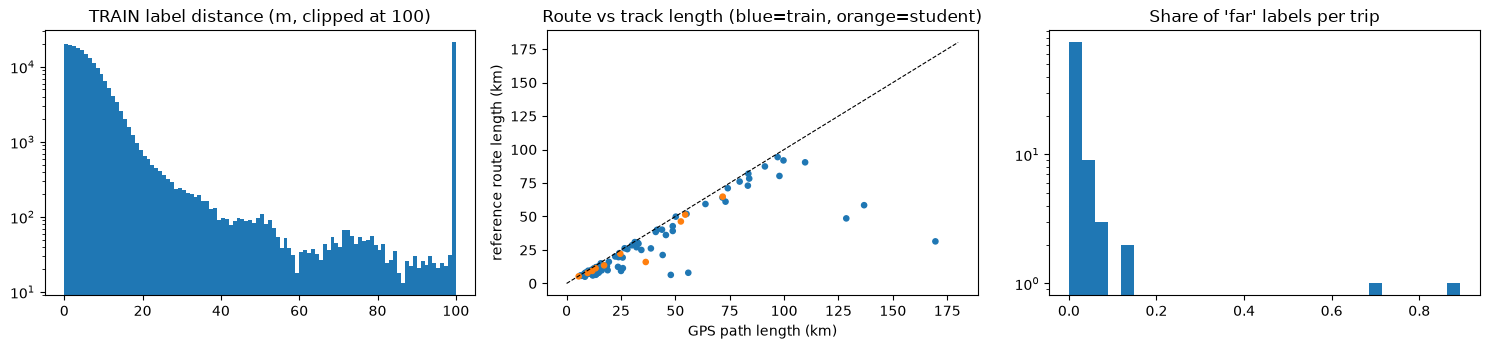

In [10]:
"""Where is the label 'far'? Trips whose reference route covers only part of the GPS track (reference-route limitation)."""
bad = V[V.share_far > .05].sort_values("share_far", ascending=False)
display(bad[["split", "trip_id", "n_points", "route_len", "share_far", "dist_mean", "route_len_m", "track_len_m", "route_to_track_len"]].round(3))
print("trips with >5%% far labels: %d ; trips with route shorter than 60%% of track length: %d" % (len(bad), int((V.route_to_track_len < .6).sum())))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist(lab["train"].label_distance_m.clip(upper=100), bins=100); ax[0].set_yscale("log"); ax[0].set_title("TRAIN label distance (m, clipped at 100)")
ax[1].scatter(V.track_len_m / 1e3, V.route_len_m / 1e3, c=(V.split == "train").map({True: "C0", False: "C1"}), s=14); ax[1].plot([0, 180], [0, 180], "k--", lw=.8)
ax[1].set_xlabel("GPS path length (km)"); ax[1].set_ylabel("reference route length (km)"); ax[1].set_title("Route vs track length (blue=train, orange=student)")
ax[2].hist(V.share_far, bins=30); ax[2].set_yscale("log"); ax[2].set_title("Share of 'far' labels per trip"); plt.tight_layout()
(VAL / "figures").mkdir(exist_ok=True); plt.savefig(VAL / "figures" / "label_validation.png", dpi=130); plt.show()

In [11]:
"""Small sensitivity check of the aligner settings on TRAINING trips only (nothing is tuned on student_test)."""
sample = SPLITS["train"][::8][:10]                                    # deterministic 10-trip subset of the training trips
grid = [dict(align_sigma_m=s, align_advance_cost=a) for s in (5.0, 10.0, 15.0) for a in (0.5, 1.0, 2.0)]
srows = []
for g in grid:
    cfg = dict(CONFIG, **g); dm, rec, far = [], [], []
    for tid in sample:
        tr = trips[("train", tid)]; route = P.load_route(DATA, "train", tid, tr.n_arcs)
        L = P.align_to_route(tr, route, flags["train"][flags["train"].trip_id == tid].reset_index(drop=True), cfg)
        dm.append(L.label_distance_m.median()); rec.append(len(np.unique(L.route_pos)) / len(route)); far.append((L.label_quality == "far").mean())
    srows.append(dict(**g, median_label_dist_m=np.mean(dm), recovered_share=np.mean(rec), far_share=np.mean(far)))
sens = pd.DataFrame(srows); sens.to_csv(VAL / "aligner_sensitivity_train.csv", index=False); display(sens.round(3))

,align_sigma_m,align_advance_cost,median_label_dist_m,recovered_share,far_share
0,5.0,0.5,4.864,0.954,0.010
1,5.0,1.0,4.862,0.952,0.010
2,5.0,2.0,4.854,0.943,0.010
3,10.0,0.5,4.934,0.961,0.010
4,10.0,1.0,4.943,0.956,0.010
5,10.0,2.0,4.910,0.943,0.010
6,15.0,0.5,4.976,0.961,0.010
7,15.0,1.0,4.991,0.954,0.010
8,15.0,2.0,4.997,0.935,0.011


In [12]:
"""Save per-point labels (train + student_test) with quality tags; candidates and features are added in 4.4+."""
for s, name in [("train", "point_labels_train"), ("student_test", "point_labels_student")]:
    lab[s].to_parquet(OUTD / f"{name}.parquet", index=False)
P.save_config(CONFIG, HERE / "preprocessing_config.json")
print({s: lab[s].shape for s in lab})

{'train': (208417, 10), 'student_test': (19160, 10)}


### Findings and decision

- Aligner output is monotone for all 90 trips. Mean share of route positions recovered: 96.8% (train) / 96.7% (student); 43/80 train and 4/10 student trips recover >= 99%. Skipped positions are rare (1,027 in train, 111 in student): arcs jumped over in one 1 s step, mostly short arcs.
- Label distance (all train points): median 5.7 m, p95 146 m, max 1,930 m; but the typical trip is much tighter (median trip p95 14.4 m). The long tail comes from a few trips (below).
- Label quality (point-weighted): train clean 80.9% / ambiguous 6.7% / far 12.4%; student clean 81.9% / ambiguous 17.3% / far 0.8%.
- Agreement with the nearest route arc on clean points: 95.3% (train) / 93.8% (student).
- **Reference-route limitation:** 7 train trips have > 5% far labels and 18 trips have a route shorter than 60% of the GPS path. Worst: 00000054 (route 31 km vs track 170 km, 89% far), 00000033 (71% far), 00000002 (14%). The reference route does not cover the whole track, so far points have no valid reference arc. They are tagged `far` and must not be counted as classifier errors without a decision (see open issues).
- Sensitivity (train only, 10 trips): sigma 5/10/15 m and advance cost 0.5/1/2 change the median label distance by < 0.15 m and recovery by < 2.6 points, so labels are not sensitive to these settings. Settings kept: sigma 10 m, advance 1.0.

## 4.3 close-out: far-point policy, threshold justification, network checks (all trips)

**Far-point policy (decided by the team lead):** far points affect LABELS, WEIGHTS and REPORTING only; they never affect candidate
generation (4.4 sees GPS + network only). TRAIN keeps all rows and down-weights far / ambiguous labels; STUDENT is never altered
(weight 1). A far label is never moved to the nearest arc.

In [13]:
"""Overall recovery of .route (collapsed labels, in order) and the per-trip worst cases."""
tv = V[V.split == "train"]; sv = V[V.split == "student_test"]
for name, d in [("train", tv), ("student_test", sv)]:
    # recovered_share = distinct route_pos hit / route length; overall = pooled over all route positions of the partition
    overall = (d.recovered_share * d.route_len).sum() / d.route_len.sum()
    print(f"{name}: pooled route recovery {overall:.3f} | per-trip median {d.recovered_share.median():.3f} min {d.recovered_share.min():.3f} "
          f"| trips < 90%: {(d.recovered_share < .9).sum()} | skipped positions {d.skipped_route_pos.sum()} of {d.route_len.sum()}")
display(V.sort_values("recovered_share").head(6)[["split", "trip_id", "route_len", "recovered_share", "skipped_route_pos", "share_far", "route_to_track_len"]].round(3))
for name, d in [("train", lab["train"]), ("student_test", lab["student_test"])]:
    x = d.label_distance_m; print(f"{name} label_distance_m: mean {x.mean():.1f} median {x.median():.1f} p95 {x.quantile(.95):.1f} max {x.max():.1f}")

train: pooled route recovery 0.965 | per-trip median 0.991 min 0.697 | trips < 90%: 8 | skipped positions 1027 of 31336
student_test: pooled route recovery 0.966 | per-trip median 0.976 min 0.914 | trips < 90%: 0 | skipped positions 111 of 3477


,split,trip_id,route_len,recovered_share,skipped_route_pos,share_far,route_to_track_len
3,train,00000004,320,0.697,96,0.045,0.916
20,train,00000026,197,0.721,54,0.000,0.912
17,train,00000022,376,0.745,95,0.002,0.954
32,train,00000039,161,0.851,23,0.000,0.957
74,train,00000093,590,0.858,83,0.032,0.900
61,train,00000078,1765,0.891,193,0.018,0.956


train label_distance_m: mean 24.1 median 5.7 p95 146.0 max 1930.4
student_test label_distance_m: mean 6.7 median 5.3 p95 16.9 max 158.2


In [14]:
"""Far-point analysis (TRAIN): which flags co-occur, which trips cause them, and how far they are."""
FL = flags["train"][["trip_id", "gps_row", "after_gap", "in_hive", "speed_jump", "stationary"]]
M = lab["train"].merge(FL, on=["trip_id", "gps_row"]); far = M[M.label_quality == "far"]
rows = [dict(flag=f, share_of_far=far[f].mean(), share_of_all_points=M[f].mean()) for f in ["after_gap", "in_hive", "speed_jump", "stationary"]]
display(pd.DataFrame(rows).round(4))
per_trip_far = far.groupby("trip_id").size().sort_values(ascending=False)
cum = [per_trip_far.head(k).sum() / per_trip_far.sum() for k in (1, 3, 5, 7)]
print(f"far points: {len(far)} of {len(M)} ({len(far)/len(M):.1%}) in {len(per_trip_far)} trips; top 1/3/5/7 trips hold {cum[0]:.1%} / {cum[1]:.1%} / {cum[2]:.1%} / {cum[3]:.1%}")
display(per_trip_far.head(7).to_frame("far_points").join(V.set_index("trip_id")[["n_points", "route_to_track_len"]]))
d = far.label_distance_m
print(f"far labels 30-50 m: {int(((d > 30) & (d <= 50)).sum())} | 50-100 m: {int(((d > 50) & (d <= 100)).sum())} | > 100 m: {int((d > 100).sum())}")
log_decision("4.3", "far_points_train", len(far), f"top-3 trips hold {cum[1]:.1%}; {int((d > 50).sum())} are > 50 m (reference route does not cover the track)")

,flag,share_of_far,share_of_all_points
0,after_gap,0.0036,0.0058
1,in_hive,0.0069,0.0020
2,speed_jump,0.0008,0.0073
3,stationary,0.0131,0.0068


far points: 25796 of 208417 (12.4%) in 56 trips; top 1/3/5/7 trips hold 66.9% / 87.2% / 92.5% / 94.8%


,far_points,n_points,route_to_track_len
trip_id,,,
00000054,17265,19313,0.185302
00000033,4160,5844,0.133288
00000084,1064,16031,0.427254
00000002,1016,7243,0.142525
00000066,351,4325,0.876341
00000021,315,15783,0.377819
00000043,293,2322,0.928939


far labels 30-50 m: 2601 | 50-100 m: 2015 | > 100 m: 21180


label distance in well-covered train trips (<=5% far): {0.5: 4.8, 0.9: 12.5, 0.95: 16.0, 0.97: 19.4, 0.98: 22.9, 0.99: 29.4, 0.995: 36.7}
label distance, ALL train points: {0.5: 5.7, 0.9: 108.6, 0.95: 146.0, 0.97: 166.5, 0.98: 174.7, 0.99: 213.5, 0.995: 261.0}
share of points with margin_nonadj < m (all train): {2: 0.074, 3: 0.103, 5: 0.135, 8: 0.161, 10: 0.173}


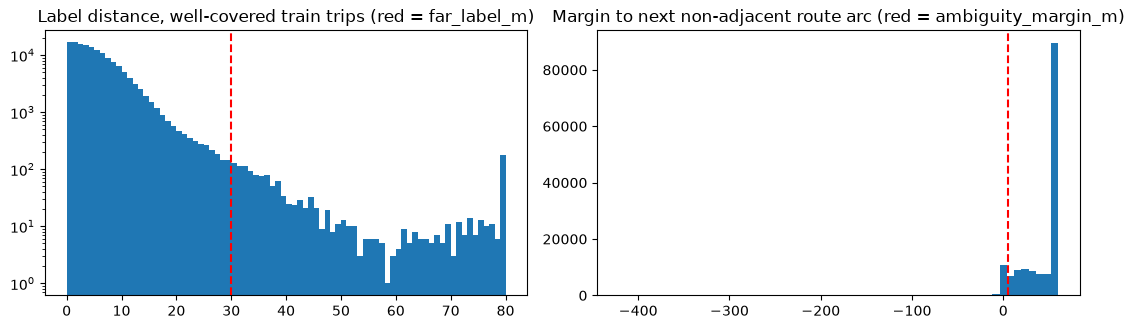

In [15]:
"""Justify far_label_m = 30 and ambiguity_margin_m = 5 from TRAINING data (not guesses)."""
covered = V[(V.split == "train") & (V.share_far <= .05)].trip_id                # trips whose route covers the whole track
G = lab["train"][lab["train"].trip_id.isin(covered)]
q = [.5, .9, .95, .97, .98, .99, .995]
print("label distance in well-covered train trips (<=5% far):", G.label_distance_m.quantile(q).round(1).to_dict())
print("label distance, ALL train points:", lab["train"].label_distance_m.quantile(q).round(1).to_dict())
print("share of points with margin_nonadj < m (all train):", {m: round(float((lab["train"].margin_nonadj_m < m).mean()), 3) for m in (2, 3, 5, 8, 10)})
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(G.label_distance_m.clip(upper=80), bins=80); ax[0].set_yscale("log"); ax[0].axvline(CONFIG["far_label_m"], c="r", ls="--"); ax[0].set_title("Label distance, well-covered train trips (red = far_label_m)")
ax[1].hist(G.margin_nonadj_m.replace(np.inf, np.nan).dropna().clip(upper=60), bins=60); ax[1].axvline(CONFIG["ambiguity_margin_m"], c="r", ls="--"); ax[1].set_title("Margin to next non-adjacent route arc (red = ambiguity_margin_m)")
plt.tight_layout(); plt.savefig(VAL / "figures" / "threshold_justification.png", dpi=130); plt.show()
p99 = G.label_distance_m.quantile(.99); p50 = G.label_distance_m.quantile(.5)
log_decision("4.3", "far_label_m", CONFIG["far_label_m"], f"p99 label distance of well-covered train trips = {p99:.1f} m")
log_decision("4.3", "ambiguity_margin_m", CONFIG["ambiguity_margin_m"], f"median label distance of well-covered train trips = {p50:.1f} m (one typical GPS error)")

In [16]:
"""Network checks on ALL 90 trips: isolated nodes, weak/strong components, route continuity, two-way share."""
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
nrows = []
for (split, tid), tr in trips.items():
    V_, A_ = len(tr.node_xy), tr.n_arcs
    g = coo_matrix((np.ones(A_), (tr.arcs[:, 0], tr.arcs[:, 1])), shape=(V_, V_)).tocsr()   # directed graph over node_id (local)
    nw, lw = connected_components(g, directed=False)                    # weak components
    ns, ls = connected_components(g, directed=True, connection="strong")   # strong components
    sw, ss = np.bincount(lw), np.bincount(ls)
    route = P.load_route(DATA, split, tid, A_)                         # route_pos -> arc_id (validation only)
    cont = float((tr.arcs[route[:-1], 1] == tr.arcs[route[1:], 0]).mean()) if len(route) > 1 else 1.0
    comp_of_route = np.unique(lw[tr.arcs[route, 0]])                   # weak components touched by the reference route
    nrows.append(dict(split=split, trip_id=tid, nodes=V_, arcs=A_, arcs_per_node=A_ / V_, isolated_nodes=int((tr.node_in_deg + tr.node_out_deg == 0).sum()),
        weak_components=nw, largest_weak_share=sw.max() / V_, strong_components=ns, largest_strong_share=ss.max() / V_,
        route_continuity=cont, route_weak_components=len(comp_of_route), two_way_arc_share=float(tr.arc_has_reverse.mean())))
N = pd.DataFrame(nrows); N.to_csv(VAL / "network_checks_all_trips.csv", index=False)
print(N.groupby("split")[["isolated_nodes", "weak_components", "largest_weak_share", "strong_components", "largest_strong_share", "route_continuity", "arcs_per_node", "two_way_arc_share"]].describe().T.round(3).to_string())
print("route continuity < 1.0 in", int((N.route_continuity < 1).sum()), "trips | route spans >1 weak component in", int((N.route_weak_components > 1).sum()), "trips | trips with isolated nodes:", int((N.isolated_nodes > 0).sum()))
display(N.sort_values("largest_strong_share").head(5)[["split", "trip_id", "nodes", "weak_components", "strong_components", "largest_weak_share", "largest_strong_share"]].round(3))
display(N.sort_values("route_continuity").head(3)[["split", "trip_id", "route_continuity", "route_weak_components"]].round(4))
log_decision("4.3", "network_checks", int(len(N)), f"isolated-node trips={int((N.isolated_nodes>0).sum())}, route-discontinuity trips={int((N.route_continuity<1).sum())}, mean two-way arc share={N.two_way_arc_share.mean():.3f}")

split                       student_test     train
isolated_nodes       count        10.000    80.000
                     mean          0.000     0.000
                     std           0.000     0.000
                     min           0.000     0.000
                     25%           0.000     0.000
                     50%           0.000     0.000
                     75%           0.000     0.000
                     max           0.000     0.000
weak_components      count        10.000    80.000
                     mean         22.700    39.012
                     std          29.182    60.682
                     min           5.000     1.000
                     25%           7.250     9.750
                     50%          11.000    20.000
                     75%          21.750    42.250
                     max         100.000   421.000
largest_weak_share   count        10.000    80.000
                     mean          0.964     0.969
                     std       

,split,trip_id,nodes,weak_components,strong_components,largest_weak_share,largest_strong_share
4,train,00000005,898,3,153,0.989,0.636
75,train,00000095,1888,7,16,0.693,0.693
84,student_test,00000052,1770,7,16,0.950,0.817
7,train,00000010,8502,28,411,0.934,0.855
12,train,00000016,8205,28,425,0.933,0.863


,split,trip_id,route_continuity,route_weak_components
60,train,00000075,0.9813,1
63,train,00000080,0.9928,1
26,train,00000033,0.9940,1


### Findings and decision

- **1.3% case:** cause = loops. The EDA's greedy monotonic rule cannot go back, so when a route starts and ends at the same place (train 00000046) it jumps to the last route position at the first fix. Not an indexing, direction or repeated-arc bug. Fix = the route-position Viterbi (global optimum), already in use; the greedy rule is not used anywhere.
- **Route recovery (collapsed, in order):** pooled 96.5% (train) / 96.6% (student); per-trip median 99.1% / 97.6%. Order is always monotone. Eight train trips are below 90%; the worst (00000004, 00000026, 00000022: 70-75%) have a step between fixes (24-33 m on average) longer than their typical arc and 22-47% of steps with dt > 1 s, so short arcs are physically skipped between two fixes. This is a sampling effect, not an alignment error.
- **Label distance:** train mean 24.1 / median 5.7 / p95 146 / max 1,930 m (inflated by uncovered trips); student mean 6.7 / median 5.3 / p95 16.9 / max 158 m.
- **Far points:** 25,796 (12.4%) in 56 trips, but 3 trips hold 87% (00000054 alone 67%) and they are trips whose route is only 13-43% of the GPS path. 91% of far labels are > 50 m (82% > 100 m) from any route arc, i.e. the reference route is missing there; only 2,601 (10%) are 30-50 m and may be real GPS error. Far points are NOT concentrated on after_gap (0.4% of far vs 0.6% of all points), speed_jump (0.1% vs 0.7%) or in_hive (0.7%); stationary 1.3% vs 0.7%. So far is a reference-coverage problem, not a flag problem.
- **Thresholds are justified by data:** far_label_m = 30 m equals the p99 label distance (29.4 m) of the 24 well-covered train trips and sits where their histogram has dropped to a thin tail; ambiguity_margin_m = 5 m is about the median label distance (4.8 m), i.e. one typical GPS error, and the ambiguous share flattens beyond ~5 m (2 m: 7.4%, 5 m: 13.5%, 10 m: 17.3%). Both kept; reasons stored in the config and the data-quality log.
- **Speed jumps vs gaps:** 0 of 1,530 (train) and 0 of 8 (student) speed jumps coincide with after_gap points, so jumps are fast roads, not gap artefacts.
- **Networks (all 90 trips):** no isolated nodes anywhere. The largest weak component holds a median 98% of nodes (worst 69%, trip 00000095); the largest strong component 96% (worst 64%, trip 00000005). 11 trips have a reference route with a few non-chained consecutive arcs (worst 98.1% continuity, trip 00000075). The reference route always stays inside one weak component. Two-way share of arcs: 92% (min 35%), about 2 arcs per node, so most roads are opposite-direction pairs and the reverse-twin feature is meaningful.
- Decision: far / ambiguous weights stored (0.3 / 0.5, train only); far points are kept, never relabelled, and never used to filter candidates.

### Folium sanity map (one train trip): GPS, reference route and aligned labels

In [17]:
"""Map of one train trip: GPS fixes (blue), reference route (green), points whose aligned arc is 'far' (red)."""
tid = SPLITS["train"][0]; tr = trips[("train", tid)]; route = P.load_route(DATA, "train", tid, tr.n_arcs)
inv_tf = Transformer.from_crs(tr.epsg, 4326, always_xy=True)
L = lab["train"][lab["train"].trip_id == tid]
m = folium.Map(location=[tr.gps_lonlat[:, 1].mean(), tr.gps_lonlat[:, 0].mean()], zoom_start=13, tiles="OpenStreetMap")
fg_route = folium.FeatureGroup("Reference route (green)"); fg_gps = folium.FeatureGroup("GPS fixes (blue)"); fg_far = folium.FeatureGroup("Far labels (red)")
for a in route:
    (lo1, la1), (lo2, la2) = inv_tf.transform(*tr.arc_a[a]), inv_tf.transform(*tr.arc_b[a])
    folium.PolyLine([(la1, lo1), (la2, lo2)], color="green", weight=4).add_to(fg_route)
for r in L.itertuples():
    lo, la = tr.gps_lonlat[r.gps_row]; far = r.label_quality == "far"
    folium.CircleMarker((la, lo), radius=2, color="red" if far else "blue", fill=True).add_to(fg_far if far else fg_gps)
for fg in (fg_route, fg_gps, fg_far): fg.add_to(m)
folium.LayerControl().add_to(m); m.save(VAL / f"sanity_map_train_{tid}.html"); m

### Findings and decision

- The map shows GPS fixes (blue), the reference route (green) and far labels (red) with a layer control. Saved as an HTML file in `cleaned_data/validation/`.

## 4.4 Candidate generation (train + student_test; ROUTE-FREE)

Candidates come from GPS + the trip's own network only. The aligned label and its distance are used **only afterwards** to *measure*
the Candidate Miss Rate; they never decide which arcs become candidates. Scheme: primary radius 50 m -> if fewer than `cand_min_candidates`
use 100 m -> if still none take the K nearest arcs; cap per point. Per-trip arc geometry is cached to disk (`cache/*.npz`); the STRtree is
rebuilt in memory (0.3 s even for the 300k-arc trip, faster than unpickling it at 1.6 s) and reused across all queries of the trip.

In [18]:
"""Observed (uncapped) candidate-count distribution on TRAIN, to justify the cap stored in CONFIG."""
cfg_unc = dict(CONFIG, cand_max_per_point=10**6)                       # no cap, only to look at the distribution
counts = []
for tid in SPLITS["train"]:
    _, pts_ = P.generate_candidates(trips[("train", tid)], None, cfg_unc); counts.append(pts_.n_candidates.to_numpy())
counts = np.concatenate(counts)
qs = {q: float(np.quantile(counts, q)) for q in (.5, .9, .95, .99, .995, .999)}
print("uncapped candidates/point (final scheme, train):", {k: round(v, 1) for k, v in qs.items()}, "max", counts.max(), "mean %.2f" % counts.mean())
cap = CONFIG["cand_max_per_point"]
print(f"CONFIG cap = {cap}: truncates {np.mean(counts > cap):.2%} of train points (the nearest {cap} arcs are always kept)")
log_decision("4.4", "cand_max_per_point", cap, f"p99 of uncapped count = {qs[.99]:.0f}; truncates {np.mean(counts > cap):.2%} of train points")

uncapped candidates/point (final scheme, train): {0.5: 6.0, 0.9: 22.0, 0.95: 28.0, 0.99: 45.8, 0.995: 54.0, 0.999: 86.0} max 148 mean 9.45
CONFIG cap = 50: truncates 0.64% of train points (the nearest 50 arcs are always kept)


In [19]:
"""Generate candidates for every train and student point with the FINAL scheme (no route is touched here)."""
cand_pairs, cand_points = {"train": {}, "student_test": {}}, {"train": {}, "student_test": {}}
t0 = time.time()
for (split, tid), tr in trips.items():
    rows = flags[split][flags[split].trip_id == tid].query("not removable").gps_row.to_numpy() if split == "train" else None   # student rows are never dropped
    pr, pt_ = P.generate_candidates(tr, rows, CONFIG)
    cand_pairs[split][tid], cand_points[split][tid] = pr, pt_
print("candidates generated in %.0fs" % (time.time() - t0))
allp = {s: pd.concat([v.assign(trip_id=k) for k, v in cand_points[s].items()], ignore_index=True) for s in cand_points}
for s in allp:
    d = allp[s]; print(s, "points", len(d), "| min candidates", int(d.n_candidates.min()), "| mean %.2f max %d" % (d.n_candidates.mean(), d.n_candidates.max()),
                       "| source share", d.candidate_source.value_counts(normalize=True).round(4).to_dict())
assert all((allp[s].n_candidates >= 1).all() for s in allp), "every point (incl. student) must have >= 1 candidate"

candidates generated in 6s
train points 208417 | min candidates 1 | mean 9.32 max 50 | source share {'primary': 0.9075, 'fallback': 0.0857, 'nearest_k': 0.0068}
student_test points 19160 | min candidates 2 | mean 10.84 max 50 | source share {'primary': 0.9995, 'fallback': 0.0005}


In [20]:
"""Candidate Miss Rate by radius and for the final scheme (TRAIN, all 80 trips), split by label quality."""
LQ = lab["train"][["trip_id", "gps_row", "arc_id", "label_distance_m", "label_quality"]].rename(columns={"arc_id": "label_arc"})
rows_out = []
for R_ in CONFIG["cand_study_radii_m"]:
    cnts = []
    for tid in SPLITS["train"]:
        tr = trips[("train", tid)]; rr, _ = P.query_radius(tr, np.arange(tr.n_gps), R_, CONFIG["cand_query_chunk_points"])
        cnts.append(np.bincount(rr, minlength=tr.n_gps))
    cnts = np.concatenate(cnts)                                          # candidates per point at radius R_ (pure radius query)
    # a label arc is a candidate at radius R iff its exact point-arc distance <= R (same arcs the query returns)
    miss = (LQ.label_distance_m > R_)
    rec = dict(scheme=f"radius {R_:g} m", mean_cand=cnts.mean(), p99_cand=np.quantile(cnts, .99), max_cand=cnts.max(), zero_cand_share=(cnts == 0).mean(),
               miss_all=miss.mean())
    for q_ in ("clean", "ambiguous", "far"): rec["miss_" + q_] = miss[LQ.label_quality == q_].mean()
    rows_out.append(rec)
# final scheme: membership of the labelled arc in the ACTUAL candidate set (includes fallback, nearest-K and the cap)
fin = pd.concat([cand_pairs["train"][t].assign(trip_id=t)[["trip_id", "gps_row", "arc_id"]] for t in SPLITS["train"]], ignore_index=True)
fin["is_label"] = 1
chk = LQ.merge(fin.rename(columns={"arc_id": "label_arc"}), on=["trip_id", "gps_row", "label_arc"], how="left")
chk["in_cand"] = chk.is_label.fillna(0).astype(bool)
pt_tr = allp["train"]
rec = dict(scheme="FINAL (50 -> 100 -> nearest-K, cap)", mean_cand=pt_tr.n_candidates.mean(), p99_cand=pt_tr.n_candidates.quantile(.99), max_cand=pt_tr.n_candidates.max(),
           zero_cand_share=0.0, miss_all=(~chk.in_cand).mean())
for q_ in ("clean", "ambiguous", "far"): rec["miss_" + q_] = (~chk.in_cand)[chk.label_quality == q_].mean()
rows_out.append(rec)
miss_tbl = pd.DataFrame(rows_out); miss_tbl.to_csv(VAL / "candidate_miss_rate_train.csv", index=False); display(miss_tbl.round(4))
src_tbl = pt_tr.merge(chk[["trip_id", "gps_row", "in_cand", "label_quality"]], on=["trip_id", "gps_row"]).groupby("candidate_source").agg(
    points=("gps_row", "size"), share=("gps_row", lambda x: len(x) / len(pt_tr)), mean_cand=("n_candidates", "mean"), miss_all=("in_cand", lambda x: 1 - x.mean()))
display(src_tbl.round(4))
print("final scheme: clean+ambiguous points missing their label arc:", int((~chk.in_cand & chk.label_quality.isin(["clean", "ambiguous"])).sum()),
      "| far points missing:", int((~chk.in_cand & (chk.label_quality == "far")).sum()))

,scheme,mean_cand,p99_cand,max_cand,zero_cand_share,miss_all,miss_clean,miss_ambiguous,miss_far
0,radius 15 m,2.8549,12.00,48,0.1362,0.1749,0.0555,0.0925,1.0000
1,radius 20 m,3.6367,16.00,68,0.1118,0.1432,0.0212,0.0349,1.0000
2,radius 30 m,5.2687,25.00,89,0.0973,0.1238,0.0000,0.0000,1.0000
3,radius 50 m,8.9587,45.00,148,0.0875,0.1113,0.0000,0.0000,0.8992
4,radius 100 m,22.3612,116.00,326,0.0068,0.1016,0.0000,0.0000,0.8211
5,"FINAL (50 -> 100 -> nearest-K, cap)",9.3229,45.84,50,0.0000,0.1037,0.0000,0.0000,0.8381


,points,share,mean_cand,miss_all
candidate_source,,,,
fallback,17856,0.0857,5.3828,0.8664
nearest_k,1413,0.0068,5.0000,0.8613
primary,189148,0.9075,9.7272,0.0261


final scheme: clean+ambiguous points missing their label arc: 0 | far points missing: 21620


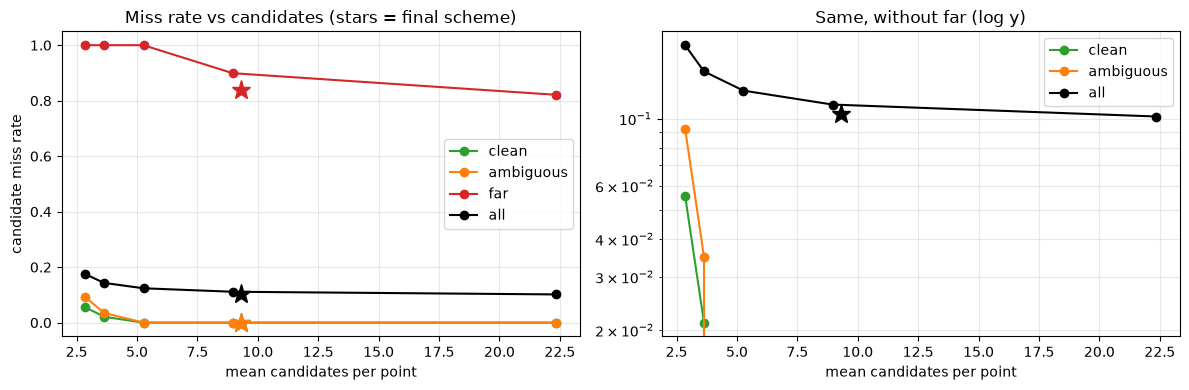

In [21]:
"""Plot miss rate vs mean candidates per point (train)."""
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
rad = miss_tbl.iloc[:-1]
for col, c in [("miss_clean", "C2"), ("miss_ambiguous", "C1"), ("miss_far", "C3"), ("miss_all", "k")]:
    ax[0].plot(rad.mean_cand, rad[col], "o-", c=c, label=col.replace("miss_", ""))
    ax[0].plot(miss_tbl.mean_cand.iloc[-1], miss_tbl[col].iloc[-1], "*", c=c, ms=14)
ax[0].set_xlabel("mean candidates per point"); ax[0].set_ylabel("candidate miss rate"); ax[0].set_title("Miss rate vs candidates (stars = final scheme)")
ax[0].legend(); ax[0].grid(alpha=.3)
for col, c in [("miss_clean", "C2"), ("miss_ambiguous", "C1"), ("miss_all", "k")]:
    ax[1].plot(rad.mean_cand, rad[col], "o-", c=c, label=col.replace("miss_", "")); ax[1].plot(miss_tbl.mean_cand.iloc[-1], miss_tbl[col].iloc[-1], "*", c=c, ms=14)
ax[1].set_yscale("log"); ax[1].set_xlabel("mean candidates per point"); ax[1].set_title("Same, without far (log y)"); ax[1].legend(); ax[1].grid(alpha=.3, which="both")
plt.tight_layout(); plt.savefig(VAL / "figures" / "miss_rate_vs_candidates.png", dpi=130); plt.show()

In [22]:
"""Student-test miss rate (DESCRIPTIVE only; nothing is tuned on it)."""
LQs = lab["student_test"][["trip_id", "gps_row", "arc_id", "label_quality"]].rename(columns={"arc_id": "label_arc"})
fs = pd.concat([cand_pairs["student_test"][t].assign(trip_id=t)[["trip_id", "gps_row", "arc_id"]] for t in SPLITS["student_test"]], ignore_index=True); fs["is_label"] = 1
cs = LQs.merge(fs.rename(columns={"arc_id": "label_arc"}), on=["trip_id", "gps_row", "label_arc"], how="left"); cs["in_cand"] = cs.is_label.fillna(0).astype(bool)
st = {"all": (~cs.in_cand).mean(), **{q_: (~cs.in_cand)[cs.label_quality == q_].mean() for q_ in ("clean", "ambiguous", "far")}}
print("student_test FINAL-scheme miss rate:", {k: round(float(v), 4) for k, v in st.items()}, "| points:", len(cs), "| mean candidates %.2f" % allp["student_test"].n_candidates.mean())
print("student quality counts:", cs.label_quality.value_counts().to_dict())
# per-trip train miss (clean+ambiguous only) -> are a few trips responsible?
pt_miss = chk[chk.label_quality.isin(["clean", "ambiguous"])].groupby("trip_id").in_cand.apply(lambda x: 1 - x.mean()).sort_values(ascending=False)
display(pt_miss.head(5).round(4).to_frame("miss_clean_amb"))

student_test FINAL-scheme miss rate: {'all': 0.0015, 'clean': 0.0, 'ambiguous': 0.0, 'far': 0.1946} | points: 19160 | mean candidates 10.84
student quality counts: {'clean': 15697, 'ambiguous': 3314, 'far': 149}


,miss_clean_amb
trip_id,
00000001,0.0
00000002,0.0
00000003,0.0
00000004,0.0
00000005,0.0


In [23]:
"""Save the per-point candidate summary (the miss rate is reproducible from it) and log the decisions."""
for s, chk_ in (("train", chk), ("student_test", cs)):
    pts_s = allp[s].merge(chk_[["trip_id", "gps_row", "label_quality", "in_cand"]].rename(columns={"in_cand": "label_in_candidates"}), on=["trip_id", "gps_row"], how="left")
    pts_s.to_parquet(OUTD / ("points_train.parquet" if s == "train" else "points_student.parquet"), index=False)   # re-written with flags in 4.7 (model_data/)
final = miss_tbl.iloc[-1]
log_decision("4.4", "miss_rate_final_train_all", round(float(final.miss_all), 5), "final scheme, all train points")
log_decision("4.4", "miss_rate_final_train_clean", round(float(final.miss_clean), 5), "final scheme, clean labels")
log_decision("4.4", "share_fallback_train", round(float((pt_tr.candidate_source == "fallback").mean()), 4), "points using the 100 m fallback")
log_decision("4.4", "share_nearest_k_train", round(float((pt_tr.candidate_source == "nearest_k").mean()), 4), "points using nearest-K")
log_decision("4.4", "miss_rate_final_student_all", round(float(st["all"]), 5), "descriptive only")
print("saved points_train.parquet / points_student.parquet")

saved points_train.parquet / points_student.parquet


### Findings and decision

- **Every point gets at least one candidate** (train min 1, student min 2). Final scheme sources (train): primary 90.8%, fallback 8.6%, nearest-K 0.7%; student: primary 99.95%, fallback 0.05%, nearest-K 0. Candidates per point: train mean 9.3, student mean 10.8, capped at 50 (the cap is about the p99 of the uncapped count, 45.8, and truncates 0.64% of train points).
- **Miss rate (train, all 208,417 points):** radius 15 / 20 / 30 / 50 / 100 m -> 17.5% / 14.3% / 12.4% / 11.1% / 10.2%; final scheme 10.4%. Mean candidates 2.9 / 3.6 / 5.3 / 9.0 / 22.4 and final 9.3.
- **Important caveat (circularity):** 'clean' and 'ambiguous' labels are, by the definition of `label_quality`, at most 30 m from their point. So their miss rate is exactly 0 at every radius >= 30 m and is not an independent result; the informative part is the small-radius rows (15 m: 5.6% of clean points missed; 20 m: 2.1%) and the far column.
- **Far points drive the whole miss rate:** at 50 m, 89.9% of far points are missed; in the final scheme 83.8% (21,620 points). These are points whose reference arc is > 50 m away (reference route not covering the track), so no radius can fix them without inflating candidates (100 m alone = 22.4 candidates/point and still misses 82.1%; the final scheme misses slightly more far points than 100 m because of the 50-candidate cap). They are not model errors and should be reported separately.
- **Confirm 50 m / 100 m:** 50 m already recovers every clean / ambiguous label and the 30-50 m far band; going to 100 m everywhere would add 13 candidates/point on average for only 2,015 more labelled points (50-100 m). The fallback is only used where the 50 m query returns fewer than 2 arcs; its labelled points are mostly far (86.6% miss), i.e. sparse-network areas. Decision: keep 50 m primary, 100 m fallback, K = 5, cap 50.
- Fallback is much more common than the EDA pilot suggested (8.6% of train points vs a 3-trip pilot at 5.5 candidates/point): the pilot trips were not representative of sparse networks. The pilot's mean of 5.5 candidates at 50 m is 9.0 over all 80 trips.
- **Student-test (descriptive only):** final-scheme miss rate 0.15% overall (clean 0, ambiguous 0, far 19.5% = 29 of 149 far points). Student has only 149 far points (0.8%), so its routes cover the tracks much better than train.
- Cap effect on the label: capping removed no clean or ambiguous label arc (miss is 0 for them in the final scheme).

## 4.5 Features per (point, candidate arc) - route-free

`pathsnap_prep.build_for_trip` builds every feature from the GPS track and the trip's own network only. It never receives `.route`.
The same code path is exposed to the API as `build_candidates_and_features(track, nodes, arcs, config)`.
Not computed here on purpose: network distance between consecutive candidates. That is the HMM transition model's job (a later stage),
and doing it here would cost a shortest-path search per consecutive candidate pair on networks of up to 300k arcs.

In [24]:
"""Build features for every train and student trip (route-free) and join the labels afterwards."""
feat = {"train": [], "student_test": []}
t0 = time.time()
for (split, tid), tr in trips.items():
    rows = flags[split][flags[split].trip_id == tid].query("not removable").gps_row.to_numpy() if split == "train" else None   # student rows never dropped
    f_, _ = P.build_for_trip(tr, rows, CONFIG)
    feat[split].append(f_)
print("features built in %.0fs" % (time.time() - t0))
feat = {s: pd.concat(v, ignore_index=True) for s, v in feat.items()}
for s in feat: print(s, feat[s].shape, "| NaN in features:", int(feat[s][P.FEATURES].isna().sum().sum()), "| rows with inf:", int(np.isinf(feat[s][P.FEATURES].to_numpy(float)).any(axis=1).sum()))
# --- verification requested for the direction features: how many arcs have an opposite-direction partner? ---
print("two-way arc share over trips (network level): mean %.3f" % N.two_way_arc_share.mean(),
      "| candidate pairs flagged is_reverse_twin: train %.3f, student %.3f" % (feat["train"].is_reverse_twin.mean(), feat["student_test"].is_reverse_twin.mean()))
print("arcs per node (mean over trips): %.2f -> roughly two arcs per node, i.e. most roads are opposite-direction pairs" % N.arcs_per_node.mean())

features built in 11s


train (1943052, 33) | NaN in features: 0 | rows with inf: 0
student_test (207713, 33) | NaN in features: 0 | rows with inf: 0
two-way arc share over trips (network level): mean 0.922 | candidate pairs flagged is_reverse_twin: train 0.763, student 0.749
arcs per node (mean over trips): 2.02 -> roughly two arcs per node, i.e. most roads are opposite-direction pairs


In [25]:
"""Join the reference labels. The label is attached AFTER feature building; features never saw it."""
cand = {}
for s in feat:
    L = lab[s][["trip_id", "gps_row", "arc_id", "label_quality", "label_distance_m"]].rename(columns={"arc_id": "label_arc"})
    c = feat[s].merge(L, on=["trip_id", "gps_row"], how="left")                       # one label per point
    c["label"] = (c.arc_id == c.label_arc).astype(np.int8)                           # 1 if this candidate is the reference arc
    cand[s] = c.drop(columns=["label_arc"])
    assert len(cand[s]) == len(feat[s]) and cand[s].label_quality.notna().all(), "label join changed the row count or lost a point"
for s in cand:
    pos_pts = cand[s].groupby("point_id").label.max()
    print(s, "pairs", len(cand[s]), "| points", len(pos_pts), "| points with a positive row", int(pos_pts.sum()), "| positives per pair %.4f" % cand[s].label.mean())
    assert cand[s].groupby("point_id").label.sum().max() <= 1, "a point has more than one positive"

train pairs 1943052 | points 208417 | points with a positive row 186797 | positives per pair 0.0961


student_test pairs 207713 | points 19160 | points with a positive row 19131 | positives per pair 0.0921


### Findings and decision

- Features were built for all 90 trips in about 10 s: train 1,943,052 candidate rows (208,417 points), student 207,713 rows (19,160 points). **No NaN and no inf** in any feature.
- **Two-way roads verified:** about 2.02 arcs per node and a mean 92.2% of arcs have an opposite-direction partner. Among actual candidate pairs, `is_reverse_twin` (the partner is also a candidate) is 76.3% in train and 74.9% in student, so most roads really appear as direction pairs and direction features matter.
- Labels were attached after the features. Each point has at most one positive row; **186,797 of 208,417 train points (89.6%) and 19,131 of 19,160 student points (99.85%) have a positive row**. Positive share per row: 9.6% (train) / 9.2% (student).
- Decision: network distance between consecutive candidates is NOT computed here (it is the HMM transition's job); the cheap temporal-context features (previous / next / windowed distance to the same arc) carry the sequence information for the classifier.

## 4.5b Feature distribution check (TRAIN only)

Usable training rows = candidate rows of train points whose label arc is in their candidate set (a point without a positive row cannot teach a
ranker). All statistics are learned on these rows only.

In [26]:
"""Class balance and the usable-row definition (TRAIN)."""
tc = cand["train"]
tc["fit_include"] = tc.groupby("point_id").label.transform("max").astype(bool)       # point has a positive candidate row
use = tc[tc.fit_include]
n_pts_all, n_pts_fit = tc.point_id.nunique(), use.point_id.nunique()
print(f"train points {n_pts_all} -> usable for fitting {n_pts_fit} ({n_pts_all - n_pts_fit} excluded: label arc not in candidate set)")
print("excluded points by label_quality:", tc[~tc.fit_include].drop_duplicates("point_id").label_quality.value_counts().to_dict())
print(f"positive share per candidate row: usable {use.label.mean():.4f} (1 positive per {1/use.label.mean():.1f} rows) | all train rows {tc.label.mean():.4f}")
CFG_NEAR_CONST, CFG_AUC_EDGE, CFG_COLLINEAR, CFG_SKEW, CFG_VIF = 0.995, 0.02, 0.95, 2.0, 10.0   # decision thresholds (reasons in the findings cell)

train points 208417 -> usable for fitting 186797 (21620 excluded: label arc not in candidate set)
excluded points by label_quality: {'far': 21620}
positive share per candidate row: usable 0.1030 (1 positive per 9.7 rows) | all train rows 0.0961


In [27]:
"""Per-feature statistics, AUC, near-constant flags (usable TRAIN rows)."""
from scipy import stats
from sklearn.metrics import roc_auc_score
rng = np.random.default_rng(CONFIG["seed"])
samp = use.sample(n=min(400_000, len(use)), random_state=CONFIG["seed"])             # fixed-seed sample for the expensive statistics
rows_ = []
for f in P.FEATURES:
    x = use[f].to_numpy(float); xs = samp[f].to_numpy(float)
    top = pd.Series(x).round(4).value_counts(normalize=True).iloc[0]
    auc = roc_auc_score(samp.label, xs) if np.nanstd(xs) > 0 else 0.5
    rows_.append(dict(feature=f, binary=bool(set(np.unique(x[:200000])) <= {0.0, 1.0}), skew=stats.skew(x), kurtosis=stats.kurtosis(x), pct_zero=100 * np.mean(x == 0),
                      pct_missing=100 * np.mean(np.isnan(x)), min=np.nanmin(x), p1=np.nanpercentile(x, 1), median=np.nanmedian(x), p99=np.nanpercentile(x, 99), max=np.nanmax(x),
                      top_value_share=top, auc=auc, auc_edge=abs(auc - .5)))
S = pd.DataFrame(rows_).set_index("feature"); display(S.round(3))

,binary,skew,kurtosis,pct_zero,pct_missing,min,p1,median,p99,max,top_value_share,auc,auc_edge
feature,,,,,,,,,,,,,
dist_m,False,0.717,3.393,0.000,0.0,0.000,0.460,25.110,63.269,238.091,0.000,0.112,0.388
frac,False,0.007,-1.813,34.238,0.0,0.000,0.000,0.493,1.000,1.000,0.342,0.502,0.002
dist_to_start_m,False,12.061,261.105,0.000,0.0,0.000,3.714,40.390,488.434,4718.752,0.000,0.531,0.031
dist_to_end_m,False,12.068,261.115,0.000,0.0,0.000,3.734,40.453,487.737,4718.752,0.000,0.528,0.028
log_arc_len,False,0.398,0.069,0.000,0.0,0.068,1.276,3.530,6.694,8.449,0.001,0.762,0.262
rank,False,1.649,2.912,10.296,0.0,0.000,0.000,6.000,41.000,49.000,0.103,0.074,0.426
dist_minus_nearest,False,0.234,-0.960,17.687,0.0,0.000,0.000,19.088,47.692,110.130,0.177,0.070,0.430
n_candidates,False,0.940,0.218,0.000,0.0,1.000,2.000,15.000,50.000,50.000,0.071,0.242,0.258
is_nearest,True,2.613,4.827,89.704,0.0,0.000,0.000,0.000,1.000,1.000,0.897,0.750,0.250


pairs with |Spearman| >= 0.95: [('heading_diff_abs', 'heading_cos', -1.0), ('is_reverse_twin', 'is_two_way', 0.999), ('after_gap', 'gap_len_s', 1.0)]


,vif
feature,
is_two_way,576.0
is_reverse_twin,573.7
heading_diff_abs,85.5
heading_cos,85.4
mean_dist_win_m,11.8
dist_m,10.1
d_next_m,6.6
d_prev_m,6.6
dist_minus_nearest,4.7


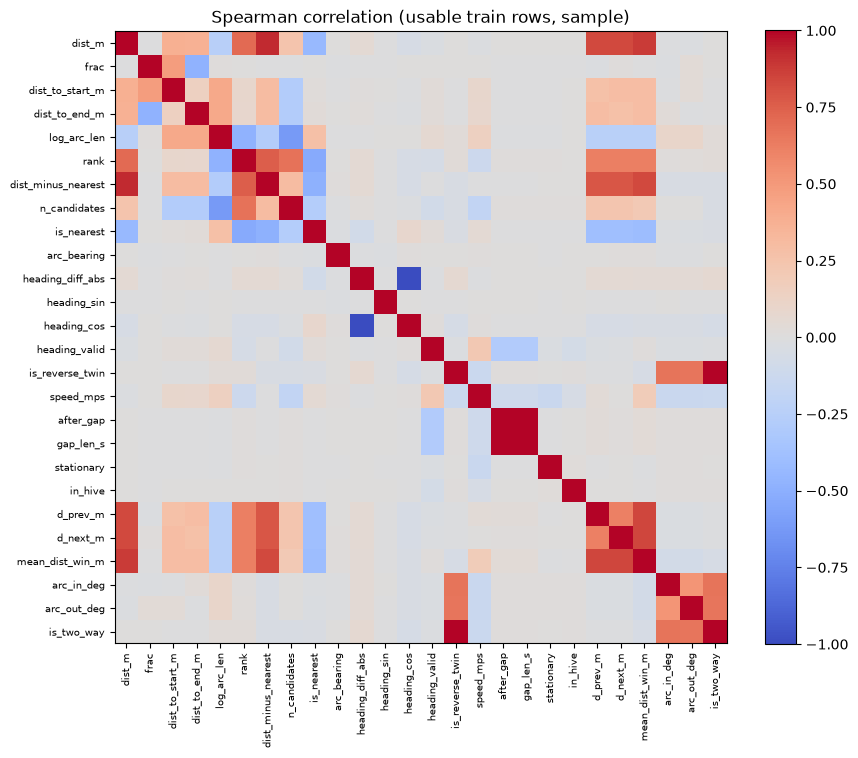

In [28]:
"""Spearman correlation and VIF on a fixed-seed sample (usable TRAIN rows)."""
from statsmodels.stats.outliers_influence import variance_inflation_factor
cont = [f for f in P.FEATURES if S.loc[f, "top_value_share"] < .99999]                # drop truly constant columns before VIF
sp = samp[P.FEATURES].corr(method="spearman")
pairs_hi = [(a, b, sp.loc[a, b]) for i, a in enumerate(P.FEATURES) for b in P.FEATURES[i + 1:] if abs(sp.loc[a, b]) >= CFG_COLLINEAR]
print("pairs with |Spearman| >= %.2f:" % CFG_COLLINEAR, [(a, b, round(float(r), 3)) for a, b, r in pairs_hi])
Xv = samp[cont].sample(n=min(60_000, len(samp)), random_state=CONFIG["seed"]).to_numpy(float)
Xv = (Xv - Xv.mean(0)) / np.where(Xv.std(0) == 0, 1, Xv.std(0))
vif = pd.Series({c: variance_inflation_factor(Xv, i) for i, c in enumerate(cont)}); S["vif"] = vif
display(S[["vif"]].sort_values("vif", ascending=False).head(10).round(1))
fig, ax = plt.subplots(figsize=(9, 7.5)); im = ax.imshow(sp.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(sp))); ax.set_xticklabels(sp.columns, rotation=90, fontsize=7); ax.set_yticks(range(len(sp))); ax.set_yticklabels(sp.index, fontsize=7)
plt.colorbar(im); ax.set_title("Spearman correlation (usable train rows, sample)"); plt.tight_layout(); plt.savefig(VAL / "figures" / "feature_spearman.png", dpi=130); plt.show()

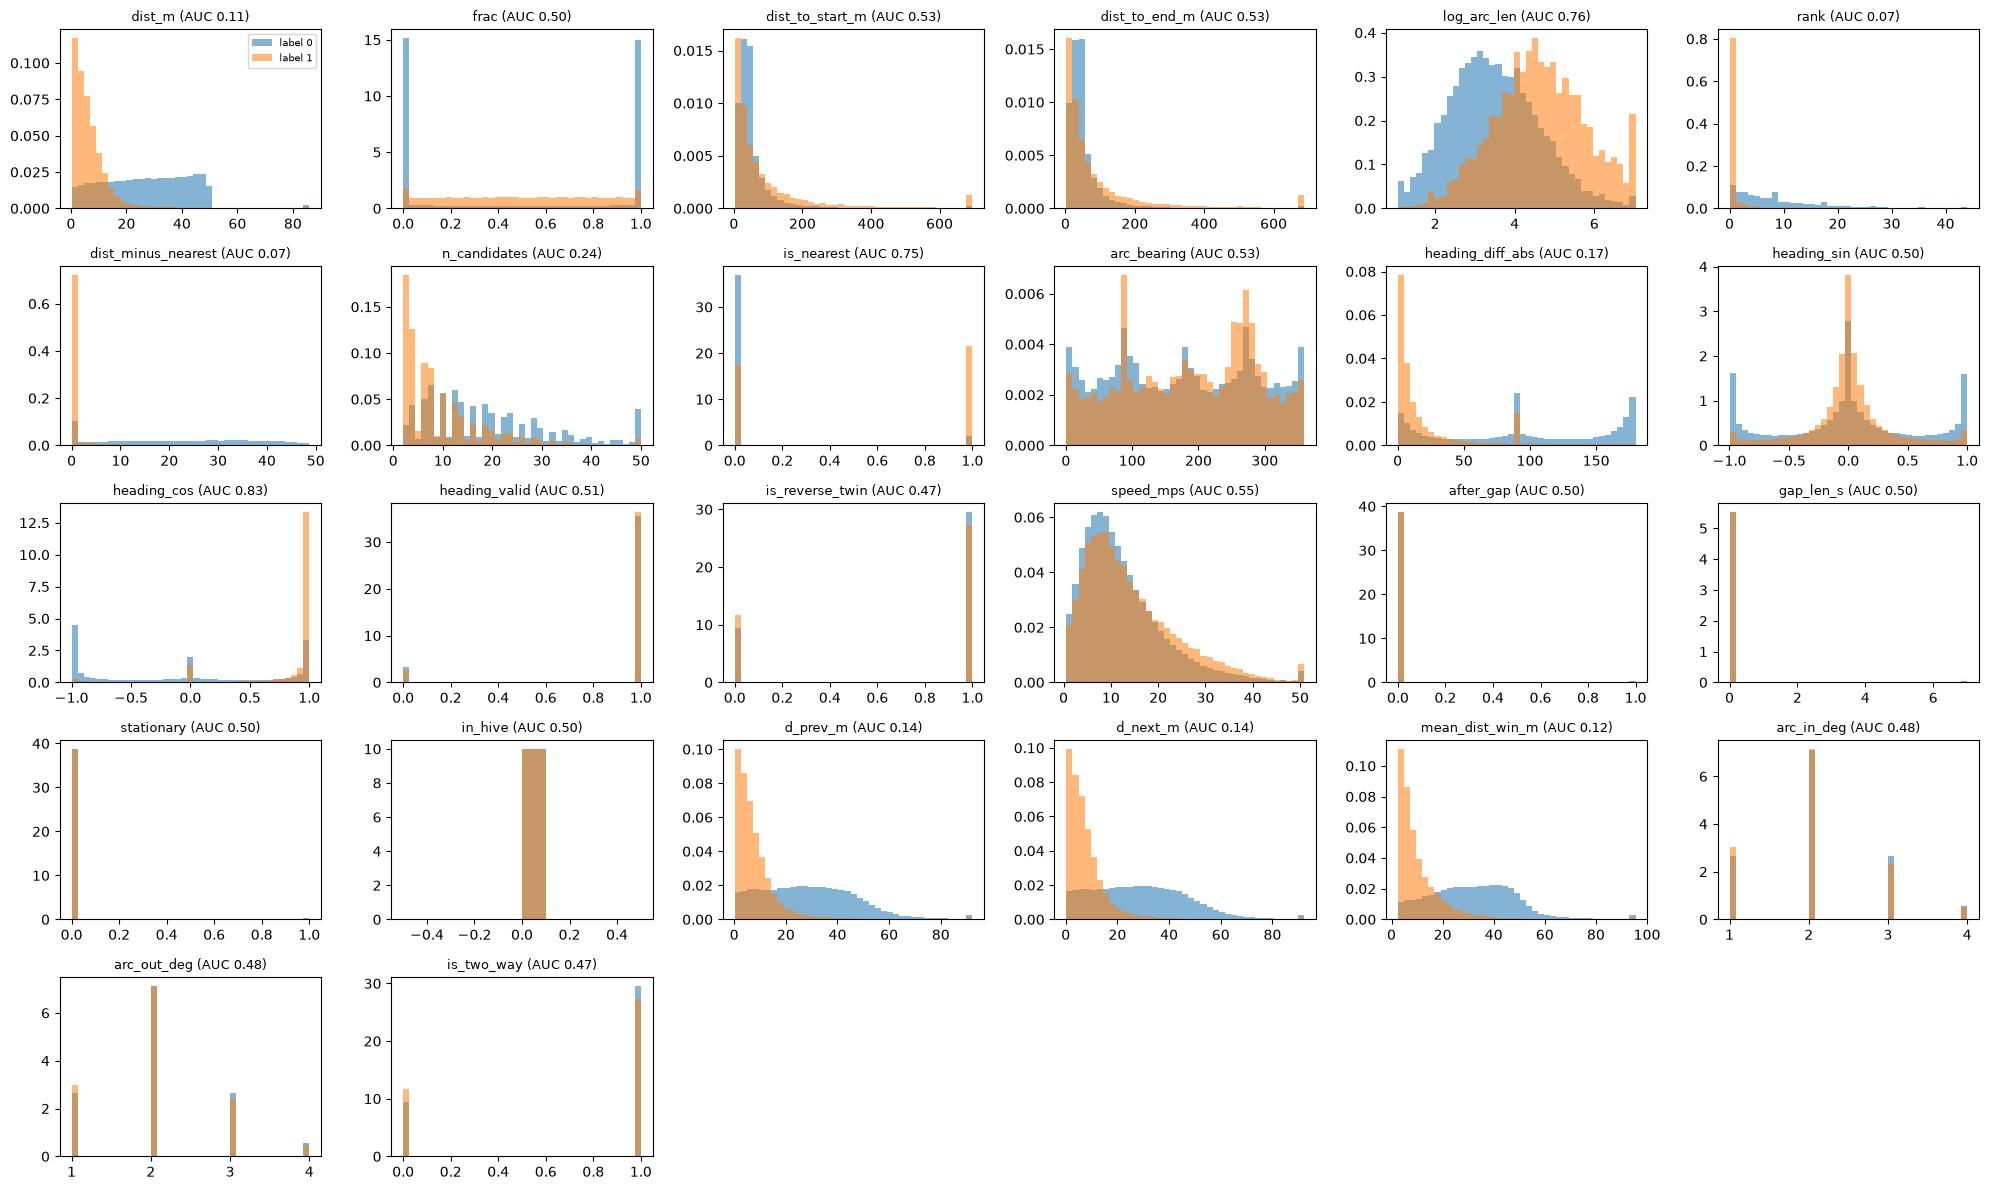

In [29]:
"""Histograms split by label (usable TRAIN sample)."""
fig, axs = plt.subplots(5, 6, figsize=(20, 12)); axs = axs.ravel()
for ax_, f in zip(axs, P.FEATURES):
    lo, hi = np.nanpercentile(samp[f], [0.5, 99.5]); b = np.linspace(lo, hi, 40) if hi > lo else 10
    ax_.hist(samp.loc[samp.label == 0, f].clip(lo, hi), bins=b, alpha=.55, density=True, label="label 0")
    ax_.hist(samp.loc[samp.label == 1, f].clip(lo, hi), bins=b, alpha=.55, density=True, label="label 1")
    ax_.set_title(f"{f} (AUC {S.loc[f, 'auc']:.2f})", fontsize=9)
for ax_ in axs[len(P.FEATURES):]: ax_.axis("off")
axs[0].legend(fontsize=7); plt.tight_layout(); plt.savefig(VAL / "figures" / "feature_hist_by_label.png", dpi=110); plt.show()

In [30]:
"""Keep / transform / drop decisions (rule-based, evidence in the table) and winsorisation bounds learned on TRAIN only."""
dec = {}
for f in P.FEATURES:
    reasons = []
    if S.loc[f, "top_value_share"] >= CFG_NEAR_CONST and S.loc[f, "auc_edge"] < CFG_AUC_EDGE: reasons.append(f"near-constant ({S.loc[f, 'top_value_share']:.1%} one value) and AUC edge {S.loc[f, 'auc_edge']:.3f} < {CFG_AUC_EDGE}")
    dec[f] = ("drop", "; ".join(reasons)) if reasons else None
for a, b, r in pairs_hi:                                                              # collinear pair: drop the less informative one
    if dec.get(a) is None and dec.get(b) is None:
        # tie-break must not depend on float noise: compare the AUC edge rounded to 3 decimals, then prefer the positively oriented feature (higher AUC)
        # full tie (rounded edge AND rounded AUC equal) -> the feature listed LATER in P.FEATURES loses, so the result never depends on float noise
        ka = (round(S.loc[a, "auc_edge"], 3), round(S.loc[a, "auc"], 3), -P.FEATURES.index(a))
        kb = (round(S.loc[b, "auc_edge"], 3), round(S.loc[b, "auc"], 3), -P.FEATURES.index(b))
        loser = a if ka < kb else b; winner = b if loser == a else a
        dec[loser] = ("drop", f"|Spearman| {abs(r):.2f} with {winner} and lower AUC edge ({S.loc[loser, 'auc_edge']:.3f} vs {S.loc[winner, 'auc_edge']:.3f})")
decision_rows = []
for f in P.FEATURES:
    if dec[f] is None:
        if (not S.loc[f, "binary"]) and S.loc[f, "skew"] > CFG_SKEW and S.loc[f, "min"] >= 0: dec[f] = ("transform", f"skew {S.loc[f, 'skew']:.1f} > {CFG_SKEW}, non-negative -> log1p")
        else: dec[f] = ("keep", "")
    decision_rows.append(dict(feature=f, decision=dec[f][0], reason=dec[f][1], skew=S.loc[f, "skew"], kurtosis=S.loc[f, "kurtosis"], pct_zero=S.loc[f, "pct_zero"], pct_missing=S.loc[f, "pct_missing"],
                              auc=S.loc[f, "auc"], vif=S.loc[f, "vif"] if f in S.vif.dropna().index else np.nan, near_constant=bool(S.loc[f, "top_value_share"] >= CFG_NEAR_CONST)))
DEC = pd.DataFrame(decision_rows); DEC.to_csv(VAL / "feature_decisions.csv", index=False); display(DEC.round(3))
DROP = DEC[DEC.decision == "drop"].feature.tolist(); LOG1P = DEC[DEC.decision == "transform"].feature.tolist(); SELECTED = [f for f in P.FEATURES if f not in DROP]
BINARY = [f for f in SELECTED if S.loc[f, "binary"]]; CONT = [f for f in SELECTED if f not in BINARY]
# winsorisation bounds: 1st / 99th percentile of the USABLE TRAIN rows (continuous features only); applied unchanged to student rows
WINSOR = {f: [float(np.nanpercentile(use[f], 100 * CONFIG["winsor_low_q"])), float(np.nanpercentile(use[f], 100 * CONFIG["winsor_high_q"]))] for f in CONT}
print("drop:", DROP, "| log1p:", LOG1P, "| binary pass-through:", BINARY, "| high-VIF (>%g):" % CFG_VIF, S.index[S.vif > CFG_VIF].tolist())
log_decision("4.5b", "features_dropped", len(DROP), ",".join(DROP) or "none")
log_decision("4.5b", "features_log1p", len(LOG1P), ",".join(LOG1P) or "none")
log_decision("4.5b", "positive_share_usable_rows", round(float(use.label.mean()), 5), "class balance per candidate row")

,feature,decision,reason,skew,kurtosis,pct_zero,pct_missing,auc,vif,near_constant
0,dist_m,keep,,0.717,3.393,0.000,0.0,0.112,10.121,False
1,frac,keep,,0.007,-1.813,34.238,0.0,0.502,1.193,False
2,dist_to_start_m,transform,"skew 12.1 > 2.0, non-negative -> log1p",12.061,261.105,0.000,0.0,0.531,1.517,False
3,dist_to_end_m,transform,"skew 12.1 > 2.0, non-negative -> log1p",12.068,261.115,0.000,0.0,0.528,1.469,False
4,log_arc_len,keep,,0.398,0.069,0.000,0.0,0.762,2.567,False
5,rank,keep,,1.649,2.912,10.296,0.0,0.074,3.613,False
6,dist_minus_nearest,keep,,0.234,-0.960,17.687,0.0,0.070,4.651,False
7,n_candidates,keep,,0.940,0.218,0.000,0.0,0.242,3.119,False
8,is_nearest,keep,,2.613,4.827,89.704,0.0,0.750,1.324,False
9,arc_bearing,keep,,0.007,-1.207,0.000,0.0,0.526,1.003,False


drop: ['heading_diff_abs', 'gap_len_s', 'in_hive', 'is_two_way'] | log1p: ['dist_to_start_m', 'dist_to_end_m'] | binary pass-through: ['is_nearest', 'heading_valid', 'is_reverse_twin', 'after_gap', 'stationary'] | high-VIF (>10): ['dist_m', 'heading_diff_abs', 'heading_cos', 'is_reverse_twin', 'mean_dist_win_m', 'is_two_way']


### Findings and decision

- **Usable training rows:** 186,797 of 208,417 train points have a positive candidate; the 21,620 excluded points are all `far` (label arc not in the candidate set, so no positive row exists). On usable rows the positive share is 10.3% (one positive per 9.7 candidate rows); class weights from train: 0.557 (negative) / 4.856 (positive).
- **Strong single features (AUC edge = |AUC - 0.5|):** `rank` (AUC 0.075) and `dist_minus_nearest` (0.071) and `dist_m` (0.113) rank the true arc near the top; `heading_cos` (0.831), `log_arc_len` (0.759), `is_nearest` (0.747) are informative too. Weak or no signal alone: `frac`, `heading_sin`, `after_gap`, `gap_len_s`, `stationary`, `in_hive` (AUC 0.50). Weak features are kept when they may help in interaction (not removed on AUC alone).
- **Dropped (4):** `heading_diff_abs` (|Spearman| 1.00 with `heading_cos`: cos is a monotone function of |difference| on [0,180]; the AUC edge is tied, so the rule keeps the positively oriented feature, i.e. the one with AUC above 0.5), `is_two_way` (|Spearman| 0.999 with `is_reverse_twin`), `gap_len_s` (|Spearman| 1.00 with `after_gap`; skew 229 and max 153,064 s), `in_hive` (99.8% one value, AUC edge < 0.02).
- **Transformed (log1p, 2):** `dist_to_start_m`, `dist_to_end_m` (skew about 12, heavy right tail up to 4.7 km). `rank`, `speed_mps` (skew 1.65 / 1.75) stay raw: below the skew 2 threshold.
- **Not dropped but flagged:** `stationary` (99.3% zeros, just under the 99.5% near-constant rule) is kept; `dist_m` VIF 10.6 and `mean_dist_win_m` VIF 11.9 are mildly collinear (matters for linear models only; trees are unaffected).
- Winsorisation bounds (1st / 99th percentile, usable train rows) are stored in the config and applied only in the scaled table. Raw table keeps all raw features.

## 4.6 Scaling, weights, folds

Two tables: **raw** (all engineered features, untouched, for tree models) and **scaled** (selected features: winsorised with train-learned bounds,
`log1p` where decided, then StandardScaler fitted on usable TRAIN rows only, binary flags passed through) for linear / MLP / distance models.

In [31]:
"""Sample weights, class weights, folds, scaler. Everything learned from TRAIN only."""
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
W_Q = {"clean": 1.0, "ambiguous": CONFIG["weight_ambiguous"], "far": CONFIG["weight_far"]}
cand["train"]["sample_weight"] = cand["train"].label_quality.map(W_Q).astype(np.float32)           # down-weight far / ambiguous labels (train only)
cand["student_test"]["sample_weight"] = np.float32(1.0)                                              # student rows always weight 1
cand["student_test"]["fit_include"] = True                                                           # never excluded; student rows are not used for fitting
aff = cand["train"].drop_duplicates("point_id").label_quality.value_counts().to_dict()
print("sample_weight applied to train POINTS by label_quality:", aff, "| weights:", W_Q)
# class weights (inverse frequency) from usable TRAIN rows
n1, n0 = int((use.label == 1).sum()), int((use.label == 0).sum())
CLASS_W = {"0": (n0 + n1) / (2 * n0), "1": (n0 + n1) / (2 * n1)}; print("class weights (train only):", {k: round(v, 3) for k, v in CLASS_W.items()})
# fixed GroupKFold by trip_id (seed 42) on usable rows -> a trip always lands in one fold; row-balanced
gkf = GroupKFold(n_splits=CONFIG["n_folds"], shuffle=True, random_state=CONFIG["seed"])
fold_of = {}
for k, (_, te) in enumerate(gkf.split(use, groups=use.trip_id)): fold_of.update({t: k for t in use.trip_id.iloc[te].unique()})
tcs = cand["train"]; tcs["fold"] = tcs.trip_id.map(fold_of).astype(np.int8); cand["student_test"]["fold"] = np.int8(-1)   # -1 = not in CV
folds = tcs.drop_duplicates("trip_id")[["trip_id", "fold"]].merge(tcs.groupby("trip_id").point_id.nunique().rename("n_points").reset_index(), on="trip_id").sort_values("trip_id")
folds.to_csv(MODEL / "folds.csv", index=False)
print("rows per fold (usable):", use.assign(fold=use.trip_id.map(fold_of)).groupby("fold").size().to_dict(), "| trips per fold:", folds.groupby("fold").size().to_dict())
assert tcs.groupby("trip_id").fold.nunique().max() == 1
log_decision("4.6", "fit_excluded_points_train", int((~tcs.drop_duplicates("point_id").fit_include).sum()), "train points whose label arc is not in the candidate set (kept in the table, fit_include=False)")
log_decision("4.6", "folds", CONFIG["n_folds"], f"GroupKFold by trip_id, shuffle, seed {CONFIG['seed']}")

sample_weight applied to train POINTS by label_quality: {'clean': 168566, 'far': 25796, 'ambiguous': 14055} | weights: {'clean': 1.0, 'ambiguous': 0.5, 'far': 0.3}
class weights (train only): {'0': 0.557, '1': 4.856}


rows per fold (usable): {0: 370536, 1: 445964, 2: 357186, 3: 294242, 4: 346358} | trips per fold: {0: 16, 1: 16, 2: 16, 3: 16, 4: 16}


In [32]:
"""Scaled table: winsorise (train bounds) -> log1p (decided) -> StandardScaler (fit on usable train rows) ; binary flags pass through."""
def to_scaled_space(df):
    """Apply the TRAIN-learned winsor bounds and log1p transforms to the continuous selected features (returns a float array)."""
    X = df[CONT].to_numpy(float).copy()
    for j, f in enumerate(CONT):
        X[:, j] = np.clip(X[:, j], *WINSOR[f])
        if f in LOG1P: X[:, j] = np.log1p(np.maximum(X[:, j], 0))
    return X
scaler = StandardScaler().fit(to_scaled_space(use))                                    # fit on usable TRAIN rows only
joblib.dump({"scaler": scaler, "continuous_features": CONT, "binary_features": BINARY, "log1p": LOG1P, "winsor": WINSOR}, MODEL / "scaler.joblib")
KEYS = ["trip_id", "point_id", "gps_row", "arc_id", "label", "label_quality"]
TAIL = ["sample_weight", "fit_include", "fold"]
scaled = {}
for s in cand:
    d = cand[s][KEYS].copy(); Xs = scaler.transform(to_scaled_space(cand[s])).astype(np.float32)
    for j, f in enumerate(CONT): d[f] = Xs[:, j]
    for f in BINARY: d[f] = cand[s][f].to_numpy()
    for c in TAIL: d[c] = cand[s][c].to_numpy()
    scaled[s] = d
chk_ = scaled["train"].loc[cand["train"].fit_include, CONT]
print("scaled TRAIN (usable) mean/std range:", float(chk_.mean().abs().max().round(4)), float(chk_.std().min().round(3)), float(chk_.std().max().round(3)))
print("scaled columns:", len(scaled["train"].columns), "| raw columns:", len(cand["train"].columns))

scaled TRAIN (usable) mean/std range: 0.0 1.0 1.0
scaled columns: 31 | raw columns: 39


### Findings and decision

- **Sample weights (train points):** clean 168,566 (weight 1.0), ambiguous 14,055 (0.5), far 25,796 (0.3). Student rows: weight 1 and `fit_include = True`; they are never excluded.
- **Exclusion:** 21,620 train points (all far) are kept in the table with `fit_include = False`; they must be filtered when fitting. This count is logged and checked by a test.
- **Folds:** GroupKFold by `trip_id`, 5 folds, seed 42, shuffled: 16 trips per fold; usable rows per fold 294k to 446k (unequal because trip sizes vary a lot). Trip-to-fold table in `model_data/folds.csv`; student rows get fold -1.
- **Scaled table:** winsorise, log1p (2 features), StandardScaler fitted on usable TRAIN rows only (check: train mean 0, std 1); 5 binary flags pass through. 22 features are selected (26 engineered minus 4 dropped): 17 continuous (scaled) + 5 binary; the exact lists are in `preprocessing_config.json`.

## 4.7 Outputs (`cleaned_data/model_data/`)

In [33]:
"""Write the model-ready tables, per-point summaries, config and the decision log."""
RAW_COLS = KEYS + P.FEATURES + P.FLAG_COLS + TAIL
for s, name in (("train", "train"), ("student_test", "student")):
    cand[s][RAW_COLS].to_parquet(MODEL / f"{name}_candidates.parquet", index=False, compression="zstd")
    scaled[s].to_parquet(MODEL / f"{name}_candidates_scaled.parquet", index=False, compression="zstd")
# one row per GPS point: n_candidates, source, label_in_candidates, flags (miss rate is reproducible from this table)
pts_out = {}
for s, fl_key in (("train", "train"), ("student_test", "student_test")):
    pp = allp[s].merge(lab[s][["trip_id", "gps_row", "arc_id", "label_quality", "label_distance_m", "route_pos"]].rename(columns={"arc_id": "label_arc_id"}), on=["trip_id", "gps_row"], how="left")
    has_pos = cand[s].groupby("point_id").label.max()
    pp["point_id"] = pp.trip_id + "_" + pp.gps_row.astype(str); pp["label_in_candidates"] = pp.point_id.map(has_pos).astype(bool)
    pp = pp.merge(flags[fl_key][["trip_id", "gps_row", "stationary", "in_hive", "after_gap", "gap_len_s", "speed_jump", "speed_outlier", "removable"]], on=["trip_id", "gps_row"], how="left")
    pp["sample_weight"] = (pp.label_quality.map(W_Q) if s == "train" else 1.0); pp["fit_include"] = pp.label_in_candidates if s == "train" else True
    pts_out[s] = pp; pp.to_parquet(MODEL / ("points_train.parquet" if s == "train" else "points_student.parquet"), index=False)
for stale in ("points_train.parquet", "points_student.parquet"):                          # the 4.4 interim copies live in model_data/ now
    if (OUTD / stale).exists(): (OUTD / stale).unlink()
# the 4.4 miss rate must be reproducible from the points table
mr = 1 - pts_out["train"].label_in_candidates.mean(); assert abs(mr - float(miss_tbl.iloc[-1].miss_all)) < 1e-9, (mr, miss_tbl.iloc[-1].miss_all)
cfg_out = dict(CONFIG, selected_features=SELECTED, dropped_features=DROP, log1p_features=LOG1P, binary_features=BINARY, continuous_features=CONT,
               winsor_bounds=WINSOR, class_weights=CLASS_W, sample_weights=W_Q, fold_seed=CONFIG["seed"], n_folds=CONFIG["n_folds"],
               feature_list=P.FEATURES, flag_columns=P.FLAG_COLS)
P.save_config(cfg_out, HERE / "preprocessing_config.json")
log_decision("4.7", "train_candidate_rows", len(cand["train"]), "rows in train_candidates.parquet")
log_decision("4.7", "student_candidate_rows", len(cand["student_test"]), "rows in student_candidates.parquet")
sizes = {p.name: round(p.stat().st_size / 1e6, 1) for p in sorted(MODEL.glob("*")) if p.is_file()}; print("MB:", sizes)

MB: {'folds.csv': 0.0, 'points_student.parquet': 0.4, 'points_train.parquet': 3.6, 'scaler.joblib': 0.0, 'student_candidates.parquet': 10.9, 'student_candidates_scaled.parquet': 9.8, 'train_candidates.parquet': 84.7, 'train_candidates_scaled.parquet': 77.5}


### Findings and decision

- Tables written to `cleaned_data/model_data/`: `train_candidates.parquet` (84.7 MB, 1,943,052 rows), `student_candidates.parquet` (10.9 MB), the two scaled versions, `points_train.parquet` / `points_student.parquet` (one row per GPS point), `folds.csv`, `scaler.joblib`; updated `preprocessing_config.json`; `data_quality_log.csv` appended with every decision.
- The 4.4 miss rate is reproduced exactly from `points_train.parquet` (asserted in the notebook).
- **Repository size decision:** the scaled TRAIN table (77.7 MB) is not committed (git-ignored); it is rebuilt exactly from the raw table and `scaler.joblib` with `pathsnap_prep.scale_features` (a test checks this on the student table). Everything else is committed.

## 4.8 Inference-safe pipeline and tests

`build_candidates_and_features(track, nodes, arcs, config)` (no route argument) is what the FastAPI backend will call; `label_trip(trip, route, config)`
is separate and only for training / server-side scoring. The assertions live in `test_pipeline.py` (also runnable with `pytest`) and run below.

In [34]:
"""Run the assertion suite (kept in test_pipeline.py so it also works outside the notebook)."""
import importlib, test_pipeline; importlib.reload(test_pipeline)
res = test_pipeline.run_all(verbose=True)
assert all(res.values()), res
log_decision("4.8", "tests_passed", sum(res.values()), "of %d" % len(res))

PASS test_inference_equals_batch
PASS test_no_route_in_inference_path
PASS test_runs_without_route_files
PASS test_index_spaces_and_projection_round_trip
PASS test_arc_geometry_lookup


PASS test_every_point_has_a_candidate_and_student_rows_kept


PASS test_exclusion_rule_is_train_only_and_logged


PASS test_scaled_table_is_reproducible_from_raw


### Findings and decision

- All 8 assertions pass: inference output equals the stored batch features for a student trip, nothing on the prediction path takes a route argument or calls `load_route` / `label_trip` / `align_to_route` (AST check), the pipeline runs from track / nodes / arcs only, index spaces and the projection round trip hold, every point (train and student) has at least one candidate, no student row was dropped (19,160 rows), the exclusion rule is train-only and its logged count equals the computed count, and the scaled table is reproducible from the raw one.

## 4.9 Folium sanity map (one train trip)

Layers: GPS points, candidate arcs (orange), aligned label arc (green), points that used the fallback or nearest-K candidates (red), points after a long gap (purple).

In [35]:
"""Pick a small train trip that has a gap and fallback points, then draw it."""
pp = pts_out["train"]; g = pp.groupby("trip_id").agg(n=("gps_row", "size"), gaps=("after_gap", "sum"), fb=("candidate_source", lambda x: (x != "primary").sum()), far=("label_quality", lambda x: (x == "far").mean()))
pick = g[(g.n < 2500) & (g.gaps > 0) & (g.fb > 0) & (g.far < .05)].sort_values("n").index
mt = pick[len(pick) // 2] if len(pick) else SPLITS["train"][0]; print("map trip:", mt, g.loc[mt].to_dict())
tr = trips[("train", mt)]; tf_ = Transformer.from_crs(tr.epsg, 4326, always_xy=True)
pm = pp[pp.trip_id == mt]; cm = cand["train"][cand["train"].trip_id == mt]
lonlat = lambda xy: [(la, lo) for lo, la in zip(*tf_.transform(xy[:, 0], xy[:, 1]))]
m = folium.Map(location=[tr.gps_lonlat[:, 1].mean(), tr.gps_lonlat[:, 0].mean()], zoom_start=14, tiles="OpenStreetMap")
fgs = {k: folium.FeatureGroup(k) for k in ["GPS points (blue)", "Candidate arcs (orange)", "Aligned label arcs (green)", "Fallback / nearest-K points (red)", "Points after a gap (purple)"]}
for a in cm.arc_id.unique():
    folium.PolyLine(lonlat(np.vstack([tr.arc_a[a], tr.arc_b[a]])), color="orange", weight=2, opacity=.6).add_to(fgs["Candidate arcs (orange)"])
for a in pm.label_arc_id.unique():
    folium.PolyLine(lonlat(np.vstack([tr.arc_a[a], tr.arc_b[a]])), color="green", weight=5, opacity=.9).add_to(fgs["Aligned label arcs (green)"])
for r_ in pm.itertuples():
    ll = (tr.gps_lonlat[r_.gps_row, 1], tr.gps_lonlat[r_.gps_row, 0])
    folium.CircleMarker(ll, radius=2, color="blue", fill=True).add_to(fgs["GPS points (blue)"])
    if r_.candidate_source != "primary": folium.CircleMarker(ll, radius=5, color="red", fill=True, popup=r_.candidate_source).add_to(fgs["Fallback / nearest-K points (red)"])
    if r_.after_gap: folium.CircleMarker(ll, radius=7, color="purple", fill=True, popup=f"gap {r_.gap_len_s:.0f}s").add_to(fgs["Points after a gap (purple)"])
for fg in fgs.values(): fg.add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
legend = """<div style="position:fixed;bottom:30px;left:30px;z-index:9999;background:white;padding:8px 10px;border:1px solid #888;font-size:12px">
<b>Trip %s</b><br><span style="color:blue">&#9679;</span> GPS point<br><span style="color:orange">&#9473;</span> candidate arc<br><span style="color:green">&#9473;</span> aligned label arc<br>
<span style="color:red">&#9679;</span> fallback / nearest-K point<br><span style="color:purple">&#9679;</span> point after a gap</div>""" % mt
m.get_root().html.add_child(folium.Element(legend)); m.save(VAL / f"sanity_map_candidates_{mt}.html")
print("saved", f"sanity_map_candidates_{mt}.html"); m

map trip: 00000057 {'n': 1645.0, 'gaps': 2.0, 'fb': 9.0, 'far': 0.01033434650455927}


saved sanity_map_candidates_00000057.html


### Findings and decision

- Map trip 00000057 (1,645 points, 2 gap points, 9 fallback / nearest-K points, 1% far labels). Layers with a legend and layer control: GPS points (blue), candidate arcs (orange), aligned label arcs (green), fallback / nearest-K points (red), points after a gap (purple). Saved to `cleaned_data/validation/sanity_map_candidates_00000057.html`.